
  Goal : uv 평면 랜드마크 registration 전처리를 통한 rppg 성능 검증.



# 모듈 import 및 사용할 영상 선택

In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"]='4'
os.environ['HDF5_USE_FILE_LOCKING'] = 'FALSE'
import h5py
import sys
import cv2
import torch
import numpy as np
from tqdm import tqdm
from pathlib import Path
import matplotlib.pyplot as plt
import gc
import pandas as pd
sys.path.append(str(Path("..").joinpath("src").absolute().resolve()))

In [2]:
h_dir = '/nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/KM_preprocess_data/nirp_cna_video_[C003_20250702].h5'
#subject_listss = sorted( [f for f in os.listdir(h_dir) ])

#h_dir = os.path.join(h_dir, subject_lists[-1])

with h5py.File(h_dir, 'r') as f_r:
    # 데이터셋 키(key) 확인 (파일 안에 어떤 데이터셋이 있는지 모를 때)
    print("Keys in H5 file:", list(f_r.keys()))
    print(f_r['video'].shape)


Keys in H5 file: ['video']
(107411, 220, 350)


In [3]:
MEDIAPIPE_UV_COORDINATES = np.array([
[0.499976992607117, 0.652534008026123], [0.500025987625122, 0.547487020492554], [0.499974012374878, 0.602371990680695], [0.482113003730774, 0.471979022026062],
[0.500150978565216, 0.527155995368958], [0.499909996986389, 0.498252987861633], [0.499523013830185, 0.40106201171875], [0.289712011814117, 0.380764007568359],
[0.499954998493195, 0.312398016452789], [0.499987006187439, 0.269918978214264], [0.500023007392883, 0.107050001621246], [0.500023007392883, 0.666234016418457],
[0.5000159740448, 0.679224014282227], [0.500023007392883, 0.692348003387451], [0.499976992607117, 0.695277988910675], [0.499976992607117, 0.70593398809433],
[0.499976992607117, 0.719385027885437], [0.499976992607117, 0.737019002437592], [0.499967992305756, 0.781370997428894], [0.499816000461578, 0.562981009483337],
[0.473773002624512, 0.573909997940063], [0.104906998574734, 0.254140973091125], [0.365929991006851, 0.409575998783112], [0.338757991790771, 0.41302502155304],
[0.311120003461838, 0.409460008144379], [0.274657994508743, 0.389131009578705], [0.393361985683441, 0.403706014156342], [0.345234006643295, 0.344011008739471],
[0.370094001293182, 0.346076011657715], [0.319321990013123, 0.347265005111694], [0.297903001308441, 0.353591024875641], [0.24779200553894, 0.410809993743896],
[0.396889001131058, 0.842755019664764], [0.280097991228104, 0.375599980354309], [0.106310002505779, 0.399955987930298], [0.2099249958992, 0.391353011131287],
[0.355807989835739, 0.534406006336212], [0.471751004457474, 0.65040397644043], [0.474155008792877, 0.680191993713379], [0.439785003662109, 0.657229006290436],
[0.414617002010345, 0.66654098033905], [0.450374007225037, 0.680860996246338], [0.428770989179611, 0.682690978050232], [0.374971002340317, 0.727805018424988],
[0.486716985702515, 0.547628998756409], [0.485300987958908, 0.527395009994507], [0.257764995098114, 0.314490020275116], [0.401223003864288, 0.455172002315521],
[0.429818987846375, 0.548614978790283], [0.421351999044418, 0.533740997314453], [0.276895999908447, 0.532056987285614], [0.483370006084442, 0.499586999416351],
[0.33721199631691, 0.282882988452911], [0.296391993761063, 0.293242990970612], [0.169294998049736, 0.193813979625702], [0.447580009698868, 0.302609980106354],
[0.392390012741089, 0.353887975215912], [0.354490011930466, 0.696784019470215], [0.067304998636246, 0.730105042457581], [0.442739009857178, 0.572826027870178],
[0.457098007202148, 0.584792017936707], [0.381974011659622, 0.694710969924927], [0.392388999462128, 0.694203019142151], [0.277076005935669, 0.271932005882263],
[0.422551989555359, 0.563233017921448], [0.385919004678726, 0.281364023685455], [0.383103013038635, 0.255840003490448], [0.331431001424789, 0.119714021682739],
[0.229923993349075, 0.232002973556519], [0.364500999450684, 0.189113974571228], [0.229622006416321, 0.299540996551514], [0.173287004232407, 0.278747975826263],
[0.472878992557526, 0.666198015213013], [0.446828007698059, 0.668527007102966], [0.422762006521225, 0.673889994621277], [0.445307999849319, 0.580065965652466],
[0.388103008270264, 0.693961024284363], [0.403039008378983, 0.706539988517761], [0.403629004955292, 0.693953037261963], [0.460041999816895, 0.557139039039612],
[0.431158006191254, 0.692366003990173], [0.452181994915009, 0.692366003990173], [0.475387006998062, 0.692366003990173], [0.465828001499176, 0.779190003871918],
[0.472328990697861, 0.736225962638855], [0.473087012767792, 0.717857003211975], [0.473122000694275, 0.704625964164734], [0.473033010959625, 0.695277988910675],
[0.427942007780075, 0.695277988910675], [0.426479011774063, 0.703539967536926], [0.423162013292313, 0.711845993995667], [0.4183090031147, 0.720062971115112],
[0.390094995498657, 0.639572978019714], [0.013953999616206, 0.560034036636353], [0.499913990497589, 0.58014702796936], [0.413199990987778, 0.69539999961853],
[0.409626007080078, 0.701822996139526], [0.468080013990402, 0.601534962654114], [0.422728985548019, 0.585985004901886], [0.463079988956451, 0.593783974647522],
[0.37211999297142, 0.47341400384903], [0.334562003612518, 0.496073007583618], [0.411671012639999, 0.546965003013611], [0.242175996303558, 0.14767599105835],
[0.290776997804642, 0.201445996761322], [0.327338010072708, 0.256527006626129], [0.399509996175766, 0.748921036720276], [0.441727995872498, 0.261676013469696],
[0.429764986038208, 0.187834024429321], [0.412198007106781, 0.108901023864746], [0.288955003023148, 0.398952007293701], [0.218936994671822, 0.435410976409912],
[0.41278201341629, 0.398970007896423], [0.257135003805161, 0.355440020561218], [0.427684992551804, 0.437960982322693], [0.448339998722076, 0.536936044692993],
[0.178560003638268, 0.45755398273468], [0.247308000922203, 0.457193970680237], [0.286267012357712, 0.467674970626831], [0.332827985286713, 0.460712015628815],
[0.368755996227264, 0.447206974029541], [0.398963987827301, 0.432654976844788], [0.476410001516342, 0.405806005001068], [0.189241006970406, 0.523923993110657],
[0.228962004184723, 0.348950982093811], [0.490725994110107, 0.562400996685028], [0.404670000076294, 0.485132992267609], [0.019469000399113, 0.401564002037048],
[0.426243007183075, 0.420431017875671], [0.396993011236191, 0.548797011375427], [0.266469985246658, 0.376977026462555], [0.439121007919312, 0.51895797252655],
[0.032313998788595, 0.644356966018677], [0.419054001569748, 0.387154996395111], [0.462783008813858, 0.505746960639954], [0.238978996872902, 0.779744982719421],
[0.198220998048782, 0.831938028335571], [0.107550002634525, 0.540755033493042], [0.183610007166862, 0.740257024765015], [0.134409993886948, 0.333683013916016],
[0.385764002799988, 0.883153975009918], [0.490967005491257, 0.579378008842468], [0.382384985685349, 0.508572995662689], [0.174399003386497, 0.397670984268188],
[0.318785011768341, 0.39623498916626], [0.343364000320435, 0.400596976280212], [0.396100014448166, 0.710216999053955], [0.187885001301765, 0.588537991046906],
[0.430987000465393, 0.944064974784851], [0.318993002176285, 0.898285031318665], [0.266247987747192, 0.869701027870178], [0.500023007392883, 0.190576016902924],
[0.499976992607117, 0.954452991485596], [0.366169989109039, 0.398822009563446], [0.393207013607025, 0.39553701877594], [0.410373002290726, 0.391080021858215],
[0.194993004202843, 0.342101991176605], [0.388664990663528, 0.362284004688263], [0.365961998701096, 0.355970978736877], [0.343364000320435, 0.355356991291046],
[0.318785011768341, 0.35834002494812], [0.301414996385574, 0.363156020641327], [0.058132998645306, 0.319076001644135], [0.301414996385574, 0.387449026107788],
[0.499987989664078, 0.618434011936188], [0.415838003158569, 0.624195992946625], [0.445681989192963, 0.566076993942261], [0.465844005346298, 0.620640993118286],
[0.49992299079895, 0.351523995399475], [0.288718998432159, 0.819945991039276], [0.335278987884521, 0.852819979190826], [0.440512001514435, 0.902418971061707],
[0.128294005990028, 0.791940987110138], [0.408771991729736, 0.373893976211548], [0.455606997013092, 0.451801002025604], [0.499877005815506, 0.908990025520325],
[0.375436991453171, 0.924192011356354], [0.11421000212431, 0.615022003650665], [0.448662012815475, 0.695277988910675], [0.4480200111866, 0.704632043838501],
[0.447111994028091, 0.715808033943176], [0.444831997156143, 0.730794012546539], [0.430011987686157, 0.766808986663818], [0.406787008047104, 0.685672998428345],
[0.400738000869751, 0.681069016456604], [0.392399996519089, 0.677703022956848], [0.367855995893478, 0.663918972015381], [0.247923001646996, 0.601333022117615],
[0.452769994735718, 0.420849978923798], [0.43639200925827, 0.359887003898621], [0.416164010763168, 0.368713974952698], [0.413385987281799, 0.692366003990173],
[0.228018000721931, 0.683571994304657], [0.468268007040024, 0.352671027183533], [0.411361992359161, 0.804327011108398], [0.499989002943039, 0.469825029373169],
[0.479153990745544, 0.442654013633728], [0.499974012374878, 0.439637005329132], [0.432112008333206, 0.493588984012604], [0.499886006116867, 0.866917014122009],
[0.49991300702095, 0.821729004383087], [0.456548988819122, 0.819200992584229], [0.344549000263214, 0.745438992977142], [0.37890899181366, 0.574010014533997],
[0.374292999505997, 0.780184984207153], [0.319687992334366, 0.570737957954407], [0.357154995203018, 0.604269981384277], [0.295284003019333, 0.621580958366394],
[0.447750002145767, 0.862477004528046], [0.410986006259918, 0.508723020553589], [0.31395098567009, 0.775308012962341], [0.354128003120422, 0.812552988529205],
[0.324548006057739, 0.703992962837219], [0.189096003770828, 0.646299958229065], [0.279776990413666, 0.71465802192688], [0.1338230073452, 0.682700991630554],
[0.336768001317978, 0.644733011722565], [0.429883986711502, 0.466521978378296], [0.455527991056442, 0.548622965812683], [0.437114000320435, 0.558896005153656],
[0.467287987470627, 0.529924988746643], [0.414712011814117, 0.335219979286194], [0.37704598903656, 0.322777986526489], [0.344107985496521, 0.320150971412659],
[0.312875986099243, 0.32233202457428], [0.283526003360748, 0.333190023899078], [0.241245999932289, 0.382785975933075], [0.102986000478268, 0.468762993812561],
[0.267612010240555, 0.424560010433197], [0.297879010438919, 0.433175981044769], [0.333433985710144, 0.433878004550934], [0.366427004337311, 0.426115989685059],
[0.396012008190155, 0.416696012020111], [0.420121014118195, 0.41022801399231], [0.007561000064015, 0.480777025222778], [0.432949006557465, 0.569517970085144],
[0.458638995885849, 0.479089021682739], [0.473466008901596, 0.545744001865387], [0.476087987422943, 0.563830018043518], [0.468472003936768, 0.555056989192963],
[0.433990985155106, 0.582361996173859], [0.483518004417419, 0.562983989715576], [0.482482999563217, 0.57784903049469], [0.42645001411438, 0.389798998832703],
[0.438998997211456, 0.39649498462677], [0.450067013502121, 0.400434017181396], [0.289712011814117, 0.368252992630005], [0.276670008897781, 0.363372981548309],
[0.517862021923065, 0.471948027610779], [0.710287988185883, 0.380764007568359], [0.526226997375488, 0.573909997940063], [0.895093023777008, 0.254140973091125],
[0.634069979190826, 0.409575998783112], [0.661242008209229, 0.41302502155304], [0.688880026340485, 0.409460008144379], [0.725341975688934, 0.389131009578705],
[0.606630027294159, 0.40370500087738], [0.654766023159027, 0.344011008739471], [0.629905998706818, 0.346076011657715], [0.680678009986877, 0.347265005111694],
[0.702096998691559, 0.353591024875641], [0.75221198797226, 0.410804986953735], [0.602918028831482, 0.842862963676453], [0.719901978969574, 0.375599980354309],
[0.893692970275879, 0.399959981441498], [0.790081977844238, 0.391354024410248], [0.643998026847839, 0.534487962722778], [0.528249025344849, 0.65040397644043],
[0.525849997997284, 0.680191040039062], [0.560214996337891, 0.657229006290436], [0.585384011268616, 0.66654098033905], [0.549625992774963, 0.680860996246338],
[0.57122802734375, 0.682691991329193], [0.624852001667023, 0.72809898853302], [0.513050019741058, 0.547281980514526], [0.51509702205658, 0.527251958847046],
[0.742246985435486, 0.314507007598877], [0.598631024360657, 0.454979002475739], [0.570338010787964, 0.548575043678284], [0.578631997108459, 0.533622980117798],
[0.723087012767792, 0.532054007053375], [0.516445994377136, 0.499638974666595], [0.662801027297974, 0.282917976379395], [0.70362401008606, 0.293271005153656],
[0.830704987049103, 0.193813979625702], [0.552385985851288, 0.302568018436432], [0.607609987258911, 0.353887975215912], [0.645429015159607, 0.696707010269165],
[0.932694971561432, 0.730105042457581], [0.557260990142822, 0.572826027870178], [0.542901992797852, 0.584792017936707], [0.6180260181427, 0.694710969924927],
[0.607590973377228, 0.694203019142151], [0.722943007946014, 0.271963000297546], [0.577413976192474, 0.563166975975037], [0.614082992076874, 0.281386971473694],
[0.616907000541687, 0.255886018276215], [0.668509006500244, 0.119913995265961], [0.770092010498047, 0.232020974159241], [0.635536015033722, 0.189248979091644],
[0.77039098739624, 0.299556016921997], [0.826722025871277, 0.278755009174347], [0.527121007442474, 0.666198015213013], [0.553171992301941, 0.668527007102966],
[0.577238023281097, 0.673889994621277], [0.554691970348358, 0.580065965652466], [0.611896991729736, 0.693961024284363], [0.59696102142334, 0.706539988517761],
[0.596370995044708, 0.693953037261963], [0.539958000183105, 0.557139039039612], [0.568841993808746, 0.692366003990173], [0.547818005084991, 0.692366003990173],
[0.52461302280426, 0.692366003990173], [0.534089982509613, 0.779141008853912], [0.527670979499817, 0.736225962638855], [0.526912987232208, 0.717857003211975],
[0.526877999305725, 0.704625964164734], [0.526966989040375, 0.695277988910675], [0.572058022022247, 0.695277988910675], [0.573521018028259, 0.703539967536926],
[0.57683801651001, 0.711845993995667], [0.581691026687622, 0.720062971115112], [0.609944999217987, 0.639909982681274], [0.986046016216278, 0.560034036636353],
[0.5867999792099, 0.69539999961853], [0.590372025966644, 0.701822996139526], [0.531915009021759, 0.601536989212036], [0.577268004417419, 0.585934996604919],
[0.536915004253387, 0.593786001205444], [0.627542972564697, 0.473352015018463], [0.665585994720459, 0.495950996875763], [0.588353991508484, 0.546862006187439],
[0.757824003696442, 0.14767599105835], [0.709249973297119, 0.201507985591888], [0.672684013843536, 0.256581008434296], [0.600408971309662, 0.74900496006012],
[0.55826598405838, 0.261672019958496], [0.570303976535797, 0.187870979309082], [0.588165998458862, 0.109044015407562], [0.711045026779175, 0.398952007293701],
[0.781069993972778, 0.435405015945435], [0.587247014045715, 0.398931980133057], [0.742869973182678, 0.355445981025696], [0.572156012058258, 0.437651991844177],
[0.55186802148819, 0.536570012569427], [0.821442008018494, 0.457556009292603], [0.752701997756958, 0.457181990146637], [0.71375697851181, 0.467626988887787],
[0.66711300611496, 0.460672974586487], [0.631101012229919, 0.447153985500336], [0.6008620262146, 0.432473003864288], [0.523481011390686, 0.405627012252808],
[0.810747981071472, 0.523926019668579], [0.771045982837677, 0.348959028720856], [0.509127020835876, 0.562718033790588], [0.595292985439301, 0.485023975372314],
[0.980530977249146, 0.401564002037048], [0.573499977588654, 0.420000016689301], [0.602994978427887, 0.548687994480133], [0.733529984951019, 0.376977026462555],
[0.560611009597778, 0.519016981124878], [0.967685997486115, 0.644356966018677], [0.580985009670258, 0.387160003185272], [0.537728011608124, 0.505385041236877],
[0.760966002941132, 0.779752969741821], [0.801778972148895, 0.831938028335571], [0.892440974712372, 0.54076099395752], [0.816350996494293, 0.740260004997253],
[0.865594983100891, 0.333687007427216], [0.614073991775513, 0.883246004581451], [0.508952975273132, 0.579437971115112], [0.617941975593567, 0.508316040039062],
[0.825608015060425, 0.397674977779388], [0.681214988231659, 0.39623498916626], [0.656635999679565, 0.400596976280212], [0.603900015354156, 0.710216999053955],
[0.81208598613739, 0.588539004325867], [0.56801301240921, 0.944564998149872], [0.681007981300354, 0.898285031318665], [0.733752012252808, 0.869701027870178],
[0.633830010890961, 0.398822009563446], [0.606792986392975, 0.39553701877594], [0.589659988880157, 0.391062021255493], [0.805015981197357, 0.342108011245728],
[0.611334979534149, 0.362284004688263], [0.634037971496582, 0.355970978736877], [0.656635999679565, 0.355356991291046], [0.681214988231659, 0.35834002494812],
[0.698584973812103, 0.363156020641327], [0.941866993904114, 0.319076001644135], [0.698584973812103, 0.387449026107788], [0.584177017211914, 0.624107003211975],
[0.554318010807037, 0.566076993942261], [0.534153997898102, 0.62064003944397], [0.711217999458313, 0.819975018501282], [0.664629995822906, 0.852871000766754],
[0.559099972248077, 0.902631998062134], [0.871706008911133, 0.791940987110138], [0.591234028339386, 0.373893976211548], [0.544341027736664, 0.451583981513977],
[0.624562978744507, 0.924192011356354], [0.88577002286911, 0.615028977394104], [0.551338016986847, 0.695277988910675], [0.551980018615723, 0.704632043838501],
[0.552887976169586, 0.715808033943176], [0.555167973041534, 0.730794012546539], [0.569944024085999, 0.767035007476807], [0.593203008174896, 0.685675978660583],
[0.599261999130249, 0.681069016456604], [0.607599973678589, 0.677703022956848], [0.631937980651855, 0.663500010967255], [0.752032995223999, 0.601315021514893],
[0.547226011753082, 0.420395016670227], [0.563543975353241, 0.359827995300293], [0.583841025829315, 0.368713974952698], [0.586614012718201, 0.692366003990173],
[0.771915018558502, 0.683578014373779], [0.531597018241882, 0.352482974529266], [0.588370978832245, 0.804440975189209], [0.52079701423645, 0.442565023899078],
[0.567984998226166, 0.493479013442993], [0.543282985687256, 0.819254994392395], [0.655317008495331, 0.745514988899231], [0.621008992195129, 0.574018001556396],
[0.625559985637665, 0.78031200170517], [0.680198013782501, 0.570719003677368], [0.64276397228241, 0.604337990283966], [0.704662978649139, 0.621529996395111],
[0.552012026309967, 0.862591981887817], [0.589071989059448, 0.508637011051178], [0.685944974422455, 0.775357007980347], [0.645735025405884, 0.812640011310577],
[0.675342977046967, 0.703978002071381], [0.810858011245728, 0.646304965019226], [0.72012197971344, 0.714666962623596], [0.866151988506317, 0.682704985141754],
[0.663187026977539, 0.644596993923187], [0.570082008838654, 0.466325998306274], [0.544561982154846, 0.548375964164734], [0.562758982181549, 0.558784961700439],
[0.531987011432648, 0.530140042304993], [0.585271000862122, 0.335177004337311], [0.622952997684479, 0.32277899980545], [0.655896008014679, 0.320163011550903],
[0.687132000923157, 0.322345972061157], [0.716481983661652, 0.333200991153717], [0.758756995201111, 0.382786989212036], [0.897013008594513, 0.468769013881683],
[0.732392013072968, 0.424547016620636], [0.70211398601532, 0.433162987232208], [0.66652500629425, 0.433866024017334], [0.633504986763, 0.426087975502014],
[0.603875994682312, 0.416586995124817], [0.579657971858978, 0.409945011138916], [0.992439985275269, 0.480777025222778], [0.567192018032074, 0.569419980049133],
[0.54136598110199, 0.478899002075195], [0.526564002037048, 0.546118021011353], [0.523913025856018, 0.563830018043518], [0.531529009342194, 0.555056989192963],
[0.566035985946655, 0.582329034805298], [0.51631098985672, 0.563053965568542], [0.5174720287323, 0.577877044677734], [0.573594987392426, 0.389806985855103],
[0.560697972774506, 0.395331978797913], [0.549755990505219, 0.399751007556915], [0.710287988185883, 0.368252992630005], [0.723330020904541, 0.363372981548309],
], dtype=np.float32)

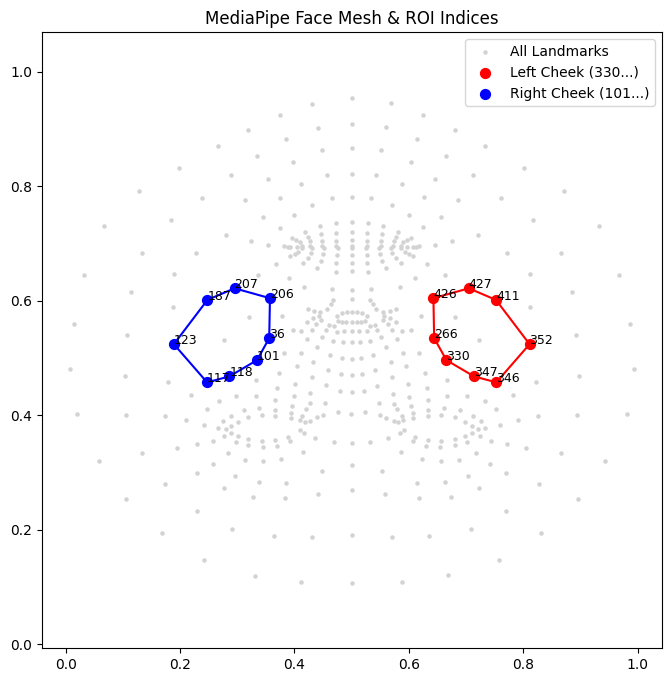

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import torch

# 1. 아까 정의한 UV 좌표 가져오기 (클래스 내부나 변수에서 가져옴)
# (여기서는 설명을 위해 detector.landmarks_uv 값을 가정합니다)
# uv_coords = detector.landmarks_uv.cpu().numpy() 
# 만약 변수가 없다면 이전 코드의 MEDIAPIPE_UV_COORDINATES 값을 그대로 쓰세요.

# (테스트를 위해 이전 답변의 텐서 값을 임시로 numpy로 변환했다고 가정)
uv_numpy = MEDIAPIPE_UV_COORDINATES

# 2. ROI 인덱스
roi_indices = {
    "Left Cheek (330...)":  [330, 347, 346, 352, 411, 427, 426, 266], 
    "Right Cheek (101...)": [101, 118, 117, 123, 187, 207, 206, 36]
}

# 3. 시각화
plt.figure(figsize=(8, 8))
plt.title("MediaPipe Face Mesh & ROI Indices")

# 전체 468개 점을 회색으로 찍기 (배경)
# UV 좌표계는 y축이 아래로 갈수록 커지므로 (1-y)를 해서 뒤집어 보여줌 (보기 편하게)
plt.scatter(uv_numpy[:, 0], uv_numpy[:, 1], s=5, c='lightgray', label='All Landmarks')

colors = ['red', 'blue']
for (name, indices), color in zip(roi_indices.items(), colors):
    # ROI 점들 추출
    roi_points = uv_numpy[indices]
    
    # 점 찍기
    plt.scatter(roi_points[:, 0], roi_points[:, 1], s=50, c=color, label=name)
    
    # 다각형 연결선 그리기 (순서대로)
    # 닫힌 도형을 만들기 위해 마지막 점과 첫 점을 이음
    loop_indices = indices + [indices[0]] 
    loop_points = uv_numpy[loop_indices]
    plt.plot(loop_points[:, 0], loop_points[:, 1], c=color, linestyle='-')
    
    # 인덱스 번호 텍스트로 표시
    for i, idx in enumerate(indices):
        plt.text(roi_points[i, 0], roi_points[i, 1], str(idx), fontsize=9, color='black')

plt.legend()
plt.axis('equal')
plt.show()

In [5]:
list(zip(roi_indices.items(),color))

[(('Left Cheek (330...)', [330, 347, 346, 352, 411, 427, 426, 266]), 'b'),
 (('Right Cheek (101...)', [101, 118, 117, 123, 187, 207, 206, 36]), 'l')]

In [5]:
# 각각의 파일 불러오기
h5_dir = '/nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/KM_preprocess_data/preprocess_result'
subject_lists = sorted( [f for f in os.listdir(h5_dir) if f.endswith('.h5') ])

all_subject_dict = {}
subject_dict = {}

for i in range(len(subject_lists)) : 
    subject_number = i
    h_dir = os.path.join(h5_dir,subject_lists[subject_number])

        
    with h5py.File(h_dir, 'r') as f_r:
        # 데이터셋 키(key) 확인 (파일 안에 어떤 데이터셋이 있는지 모를 때)
        #print("Keys in H5 file:", list(f_r.keys()))
        print(f"{i} ,subject_num : {subject_lists[i]} ,결과 shape : {f_r['nir_uv_data'].shape}, 랜드마크 추출 성공 비율 : {100 - f_r['valid_mask'].attrs['fail_rate']}")
        
        # subject_dict = {
        #     'data' : f_r['nir_uv_data'][()],
        #     'valid_mask' : f_r['valid_mask'][()],
        #     'fail_rate' : f_r['valid_mask'].attrs['fail_rate']
        # }


        # all_subject_dict[subject_lists[i].split('[')[-1].split(']')[0]] = subject_dict
        # subject_dict = {}




0 ,subject_num : nirp_cna_video_[A001_20250609].h5 ,결과 shape : (107727, 64, 64), 랜드마크 추출 성공 비율 : 97.77678751945496
1 ,subject_num : nirp_cna_video_[A002_20250609].h5 ,결과 shape : (114227, 64, 64), 랜드마크 추출 성공 비율 : 88.54736614227295
2 ,subject_num : nirp_cna_video_[A004_20250610].h5 ,결과 shape : (114422, 64, 64), 랜드마크 추출 성공 비율 : 100.0
3 ,subject_num : nirp_cna_video_[A005_20250611].h5 ,결과 shape : (120275, 64, 64), 랜드마크 추출 성공 비율 : 64.69341278076172
4 ,subject_num : nirp_cna_video_[A006_20250611].h5 ,결과 shape : (104291, 64, 64), 랜드마크 추출 성공 비율 : 99.97698746807873
5 ,subject_num : nirp_cna_video_[A007_20250612].h5 ,결과 shape : (120592, 64, 64), 랜드마크 추출 성공 비율 : 53.28711700439453
6 ,subject_num : nirp_cna_video_[A008_20250612].h5 ,결과 shape : (116806, 64, 64), 랜드마크 추출 성공 비율 : 59.46184539794922
7 ,subject_num : nirp_cna_video_[B001_20250623].h5 ,결과 shape : (117048, 64, 64), 랜드마크 추출 성공 비율 : 99.84365390241146
8 ,subject_num : nirp_cna_video_[B002_20250623].h5 ,결과 shape : (119636, 64, 64), 랜드마크 추출 성공 

In [116]:
h5_dir = '/nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/KM_preprocess_data/preprocess_result'
subject_lists = sorted( [f for f in os.listdir(h5_dir) if f.endswith('.h5') ])

subject_num = 4 ######################################################### subject 설정 #########################################################
subject_id = subject_lists[subject_num].split('[')[1].split(']')[0]

print(f"subject id : {subject_id}")
h_dir = os.path.join(h5_dir,subject_lists[subject_num])

    
with h5py.File(h_dir, 'r') as f_r:
    # 데이터셋 키(key) 확인 (파일 안에 어떤 데이터셋이 있는지 모를 때)
    #print("Keys in H5 file:", list(f_r.keys()))
    
    subject_dict = {
        'data' : f_r['nir_uv_data'][()],
        'valid_mask' : f_r['valid_mask'][()],
        'fail_rate' : f_r['valid_mask'].attrs['fail_rate']
        }




sub_data = subject_dict['data'] #(T, 64, 64)
sub_valid = subject_dict['valid_mask']
sub_fr = subject_dict['fail_rate']

subject id : A006_20250611


(104291, 64, 64) float32


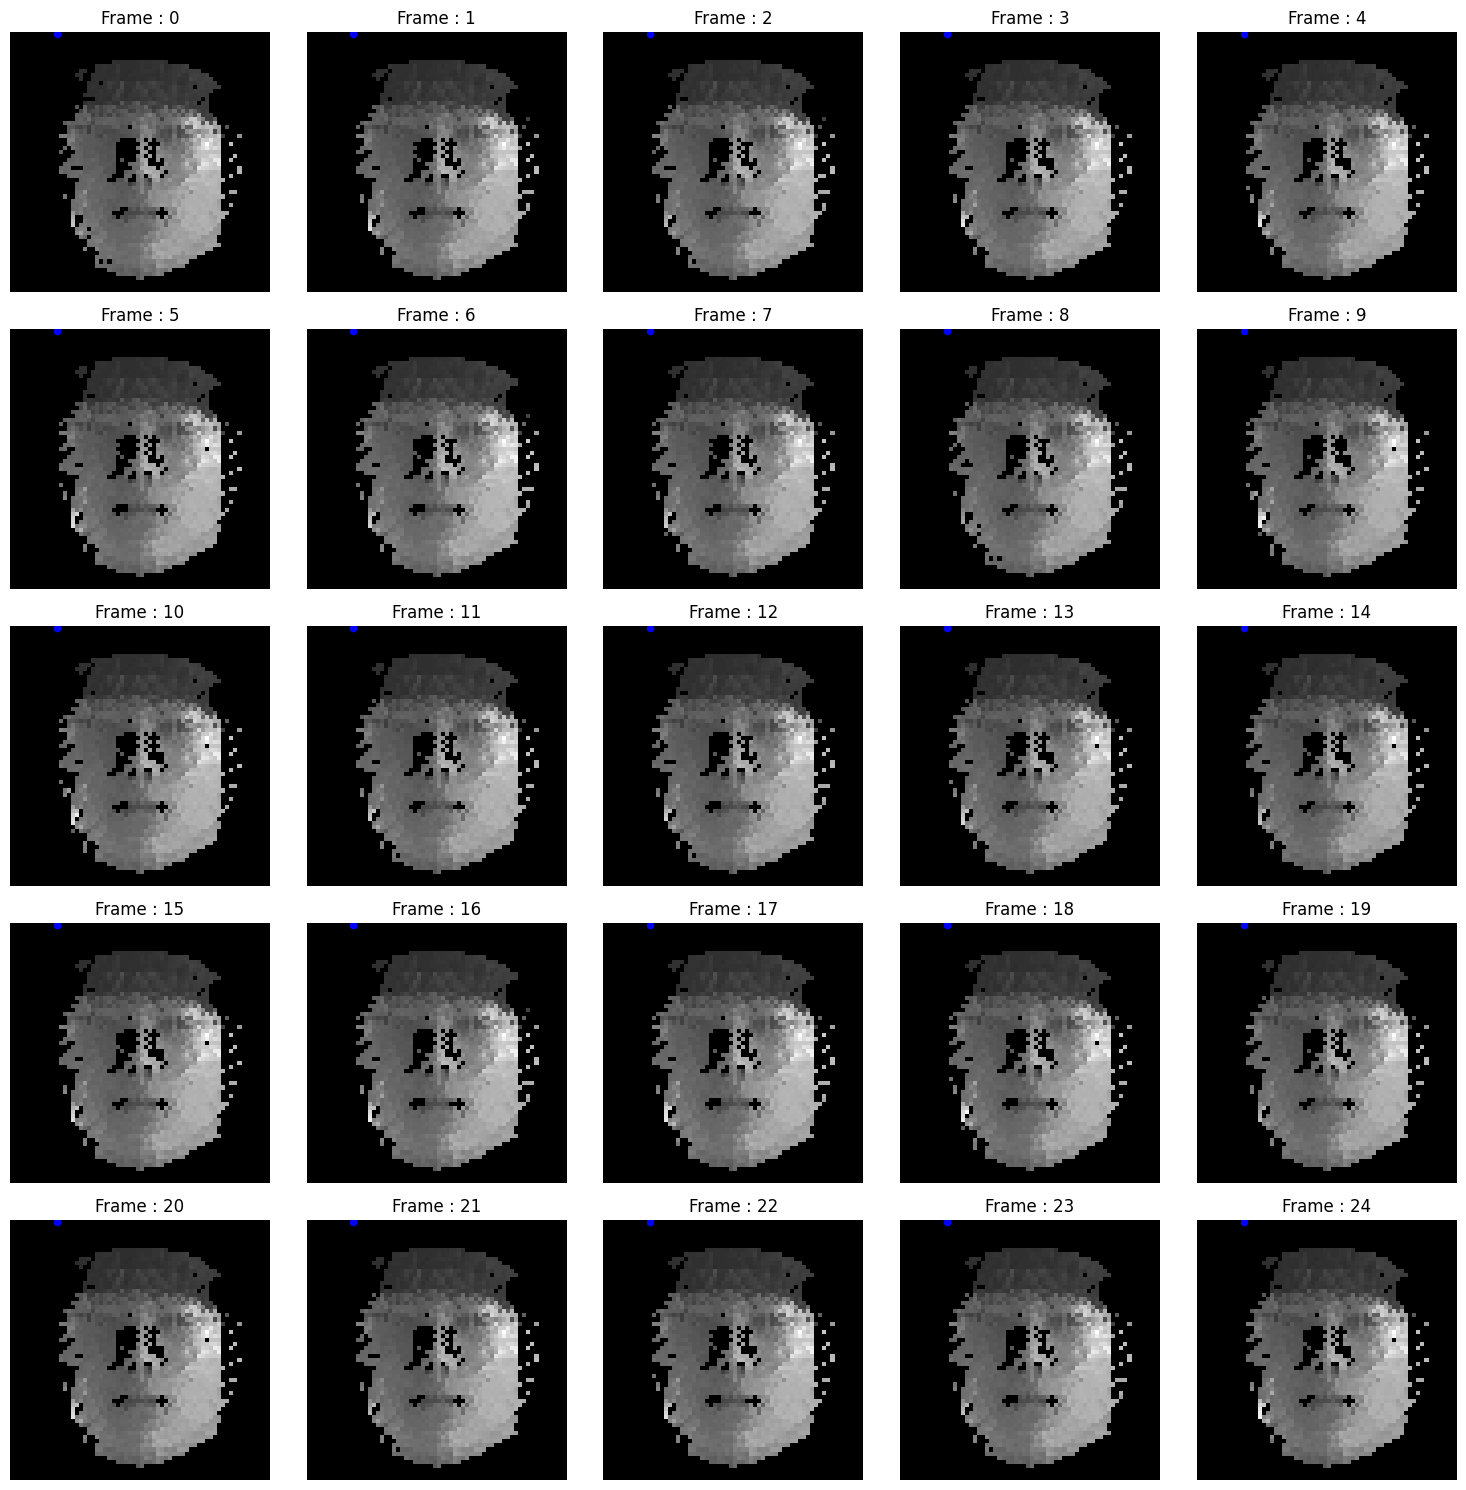

In [150]:
roi_point = (uv_numpy[425] * 64).astype(int)
print(sub_data.shape, sub_data.dtype)
aaa = 900*113
f_ex = sub_data[aaa : aaa+25 ]


roi_r_ls = [101, 118, 117, 123, 187, 207, 206, 36]
roi_l_ls = [330, 347, 346, 352, 411, 427, 426, 266]
roi_ls_all = roi_r_ls + roi_l_ls

roi_coords = (uv_numpy[roi_ls_all] ).astype(int)
roi_rows = roi_coords[:,0]
roi_cols = roi_coords[:,1]



# 2. ROI 인덱스
colors = ['red', 'blue']
uv_numpy = (MEDIAPIPE_UV_COORDINATES * 64).astype(int)

roi_indices = {
    "Left Cheek (330...)":  [330, 347, 346, 352, 411, 427, 426, 266], 
    "Right Cheek (101...)": [101, 118, 117, 123, 187, 207, 206, 36]
}

fig, axes = plt.subplots(5,5, figsize=(15,15)) #fig 가 전체 사진 , axes 가 subplot들 각각 한 칸
axes = axes.flatten()


for i, f in enumerate(f_ex) : 
    axes[i].imshow(f, cmap = 'gray')
    axes[i].set_title(f"Frame : {i}")
    axes[i].axis('off')

        # ROI 점들 추출
    roi_points = uv_numpy[roi_ls_all]
        
        # 점 찍기
    axes[i].scatter(11 , 0 , s =20, c = 'blue')
        
        #axes[i].scatter(roi_points[:,0], roi_points[:,1], s =20, c = color, label = name)
plt.tight_layout()
plt.show()




In [148]:
roi_rows

array([21, 18, 15, 12, 15, 18, 22, 22, 42, 45, 48, 51, 48, 45, 41, 41])

# ppg / rppg preprocessing

### 랜드마크 추출안되는 프레임 확인

[   576    577    578 ... 117203 117204 117207]


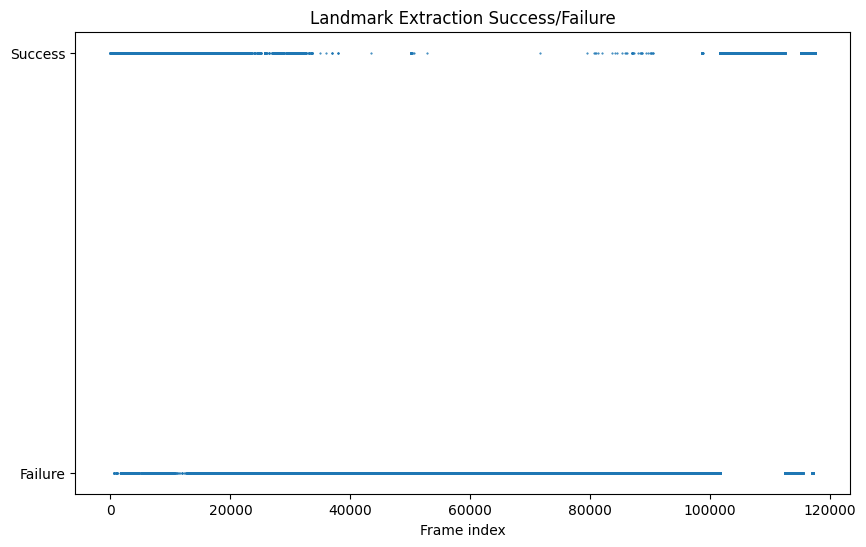

In [106]:
failed_indices = np.where(sub_valid == False)[0]
print(failed_indices)
plt.figure(figsize=(10, 6))
plt.plot(sub_valid, 'o', ms = 0.5, ls ='')

plt.yticks([0,1],['Failure', 'Success'])
plt.xlabel('Frame index')
plt.title('Landmark Extraction Success/Failure')
plt.show()

In [30]:
print(len(failed_indices))

42465


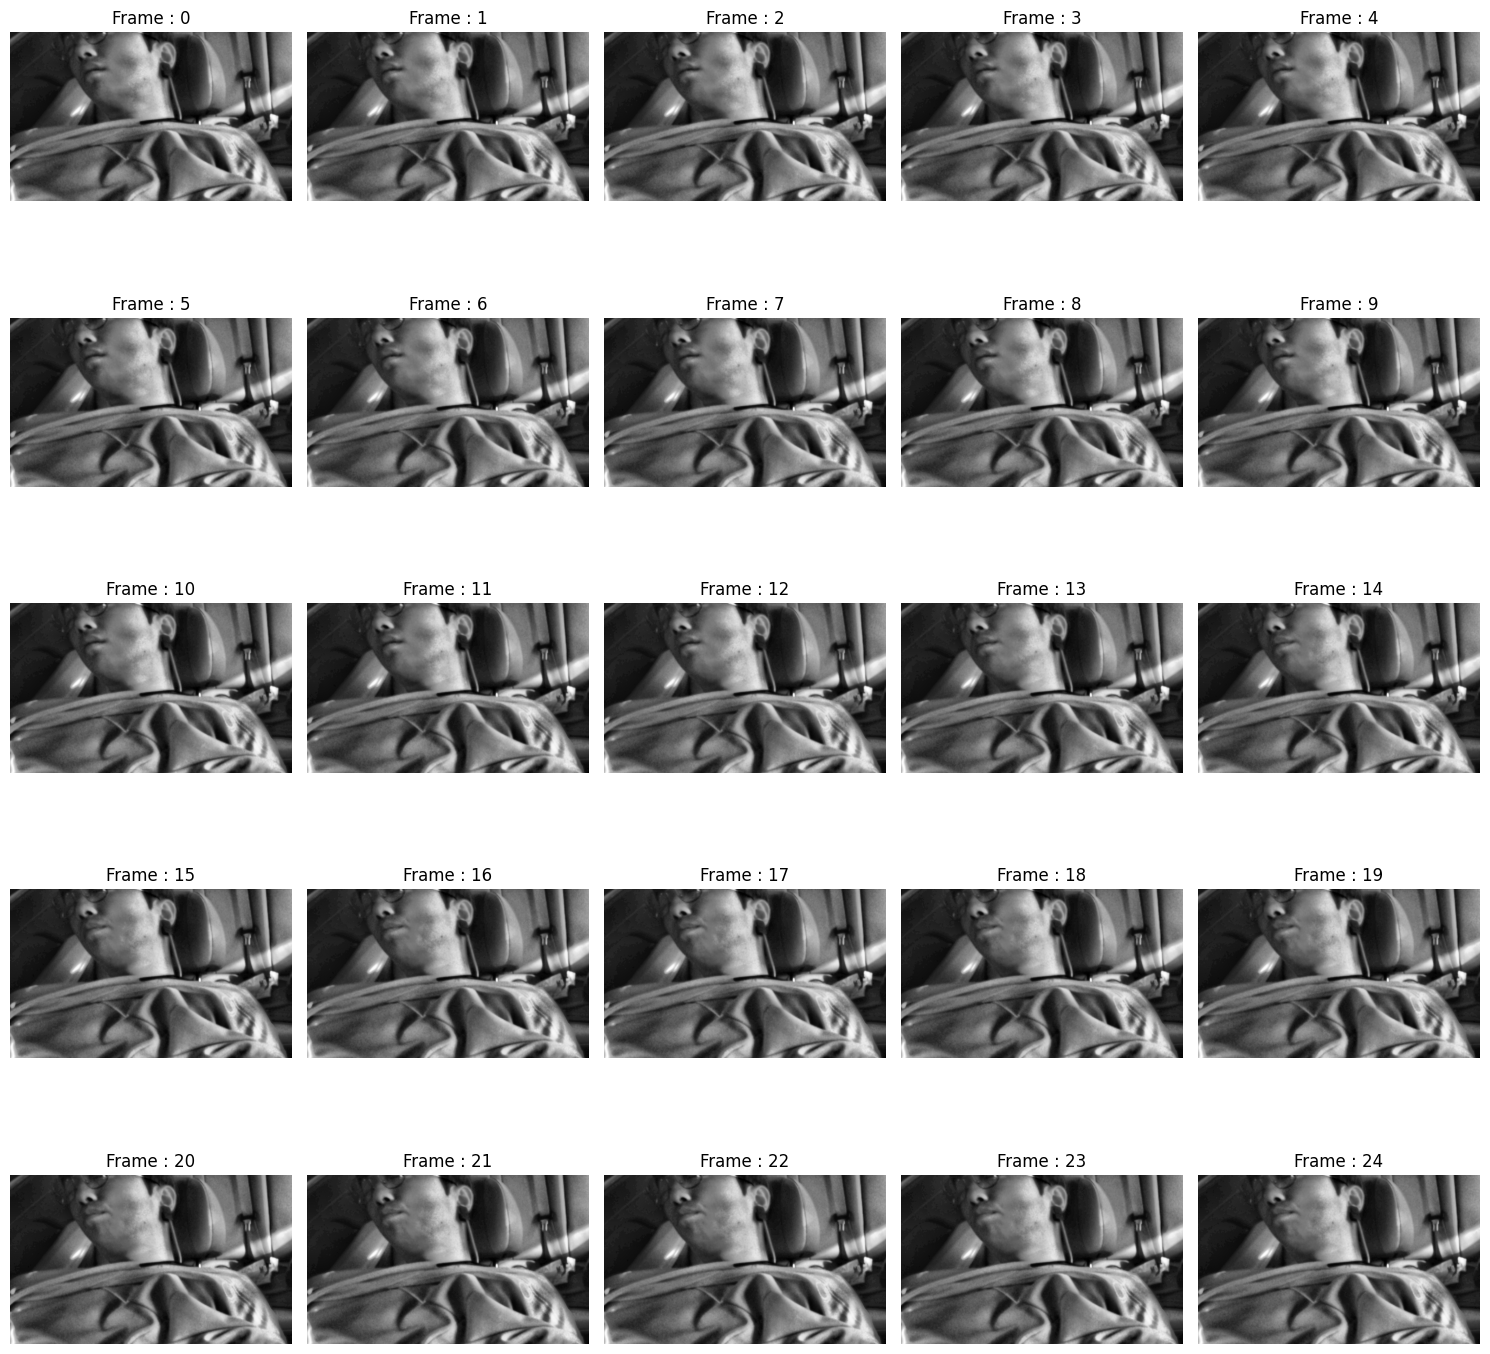

In [94]:

# CLAHE 객체 생성
clahe = cv2.createCLAHE(clipLimit=7.0, tileGridSize=(8, 8))

basse_dir = '/nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/videos/'
dddir = os.path.join(basse_dir, subject_id, 'NIR')
aa = sorted(os.listdir(dddir))
aa = np.array(aa)
f_ex = aa[failed_indices[-100:-75]]

fig, axes = plt.subplots(5, 5, figsize=(15, 15))
axes = axes.flatten()

for i, f in enumerate(f_ex):
    # [수정] cv2.IMREAD_GRAYSCALE을 추가하여 처음부터 1채널로 읽어옵니다.
    iomg = cv2.imread(os.path.join(dddir, f), cv2.IMREAD_GRAYSCALE)
    
    if iomg is None: continue # 파일 로드 실패 방지
    
    # 크롭 (그레이스케일 이미지이므로 채널 고민 없이 슬라이싱 가능)
    iomg = iomg[:300, 50:550]
    
    # [해결] 이제 1채널이므로 clahe.apply가 정상 작동합니다.
    iomg_enhanced = clahe.apply(iomg)
    
    axes[i].imshow(iomg_enhanced, cmap='gray')
    axes[i].set_title(f"Frame : {i}")
    axes[i].axis('off')

plt.tight_layout()
plt.show()

구간길이별 개수

랜드마크 실패구간 총 개수 : 8206


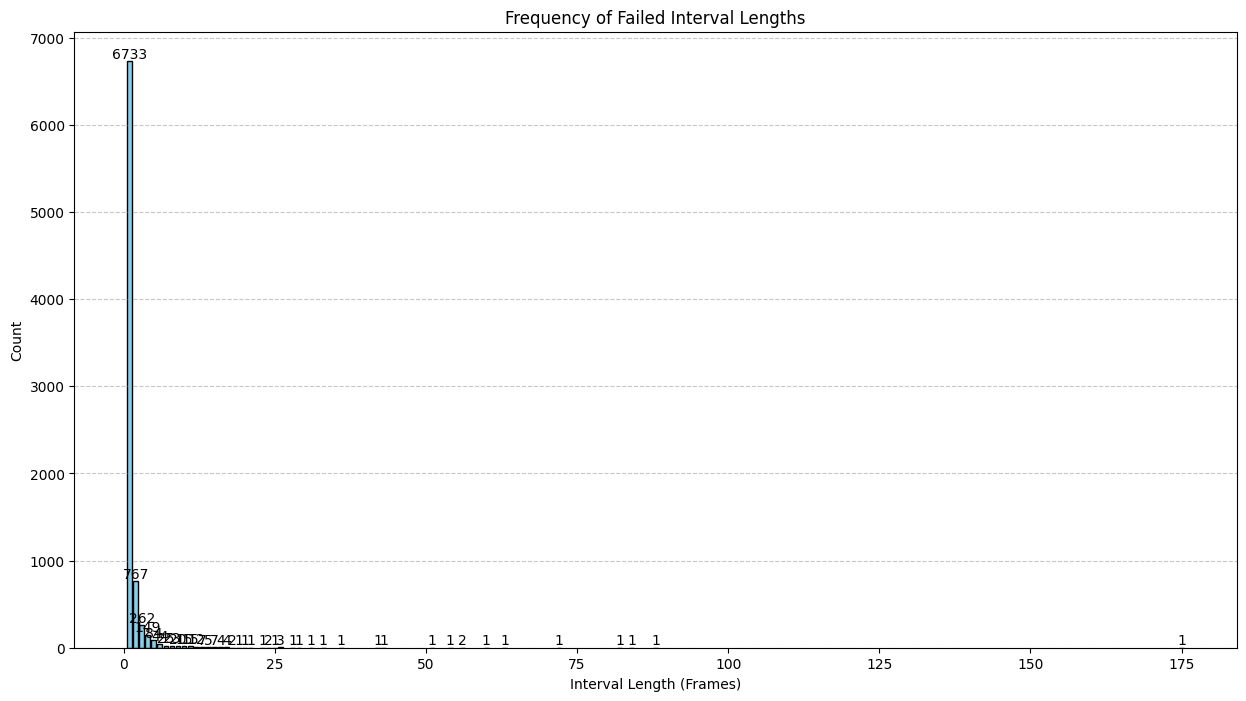

In [23]:
from collections import Counter

failed_intervals = []
fail_list = []

for i in range(len(failed_indices)) :
    fail_list.append(failed_indices[i])
    if  i == len(failed_indices)-1 or failed_indices[i]+1 != failed_indices[i+1] :
        failed_intervals.append(fail_list)
        fail_list = []
    else : 
        continue        

failed_interaval_size = []
for interval in failed_intervals :
    failed_interaval_size.append(len(interval))

print(f'랜드마크 실패구간 총 개수 : {len(failed_intervals)}')    

# 1. 구간 길이별로 개수 세기 (예: {1: 50번, 2: 10번, ...})
length_counts = Counter(failed_interaval_size)

# 2. X축(길이) 기준으로 정렬 (1, 2, 3, 4 ... 순서대로)
sorted_counts = sorted(length_counts.items()) 

# 3. 데이터 분리
lengths, frequencies = zip(*sorted_counts)

# 4. 막대그래프 그리기
plt.figure(figsize=(15, 8))
bar_plot = plt.bar(lengths, frequencies, color='skyblue', edgecolor='black')

# 5. 그래프 꾸미기
plt.title("Frequency of Failed Interval Lengths") # 실패 구간 길이별 빈도
plt.xlabel("Interval Length (Frames)")            # 구간 길이 (프레임 수)
plt.ylabel("Count")                               # 발생 횟수
plt.grid(axis='y', linestyle='--', alpha=0.7)


# (선택) 막대 위에 숫자 표시
for rect in bar_plot:
    height = rect.get_height()
    plt.text(rect.get_x() + rect.get_width()/2.0, height, '%d' % int(height), ha='center', va='bottom')

plt.show()

In [315]:
print(sorted_counts)

[(1, 2), (3, 1), (4, 2), (5, 1), (10, 1), (13, 2), (18, 2), (23, 1), (28, 1), (33, 1), (34, 1), (38, 1), (46, 1), (136, 1), (138, 1), (154, 1), (165, 1), (172, 1), (254, 1), (274, 1), (280, 1), (284, 1), (332, 1), (337, 1), (396, 1), (431, 1), (494, 1), (539, 1), (818, 1), (1214, 1), (1266, 1), (1350, 1), (1368, 1), (1526, 1), (1703, 1), (3423, 1), (3623, 1), (3912, 1), (3922, 1), (4069, 1), (9593, 1)]


### rppg 추출(std)

상위 1위 좌표: UV(32, 46), 분산값: 0.038989
상위 2위 좌표: UV(31, 43), 분산값: 0.038501
상위 3위 좌표: UV(31, 44), 분산값: 0.037364
상위 4위 좌표: UV(31, 45), 분산값: 0.036636
상위 5위 좌표: UV(27, 46), 분산값: 0.036196


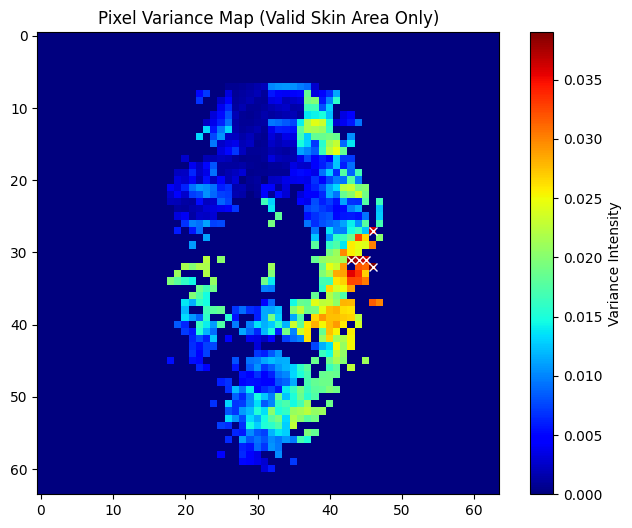

In [193]:
#얼굴 픽셀중 std가 높은 상위값 추출

# 데이터 준비 (T, H, W) 형태라고 가정
data = sub_data
T, H, W = data.shape

# 1. 픽셀별 가시성 확인 (마스킹된 프레임 제외)
# 2,000프레임 중 1,800프레임(90%) 이상 값이 있는 픽셀만 골라냄 >>> 수정해야됨 
visibility = (data > 0).sum(axis=0)
valid_maskk = visibility > (T * 0.875)

# 2. 유효 픽셀들의 분산(Variance) 계산
# 마스킹된 영역은 계산에서 제외하기 위해 valid_mask를 곱해줌
pixel_variance = np.var(data, axis = 0) * valid_maskk

# 3. 변동성 상위 5개 좌표 찾기
flat_indices = np.argsort(pixel_variance.flatten())[::-1]
top_coords = []
for i in range(5):
    idx = flat_indices[i]
    y, x = divmod(idx, W)
    top_coords.append((y, x))
    print(f"상위 {i+1}위 좌표: UV({y}, {x}), 분산값: {pixel_variance[y, x]:.6f}")

# 4. 변동성 지도(Heatmap) 시각화
plt.figure(figsize=(8, 6))
plt.imshow(pixel_variance, cmap='jet')
plt.colorbar(label='Variance Intensity')
for y, x in top_coords:
    plt.plot(x, y, 'wx')  # 상위 좌표 흰색 X로 표시
plt.title("Pixel Variance Map (Valid Skin Area Only)")
plt.show()

top4_coor = []
coor_rc = []
for t in range(4) : 
    for j in range(2) :
        coor_rc.append(top_coords[t][j])
    top4_coor.append(coor_rc)
    coor_rc = []
    

#top_std_r , top_std_c = top_coords[0][0], top_coords[0][1]


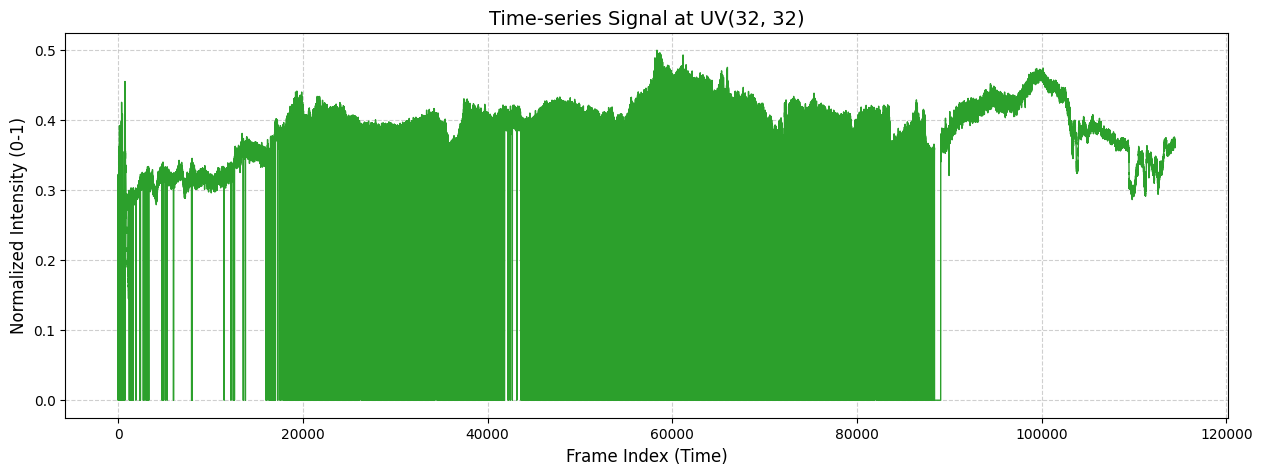

In [57]:
# test at one point
reg = data[:, 30 , 50 ]
reg.shape
reg = reg

# 2. 간단한 시계열 플롯 생성
plt.figure(figsize=(15, 5))
plt.plot(reg, color='#2ca02c', linewidth=1) # rPPG 시각화에 자주 쓰이는 초록 계열

# 3. 그래프 정보 설정
plt.title("Time-series Signal at UV(32, 32)", fontsize=14)
plt.xlabel("Frame Index (Time)", fontsize=12)
plt.ylabel("Normalized Intensity (0-1)", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)

# 4. y축 범위 자동 최적화 (미세한 변화를 보기 위함)
# 만약 정규화된 값의 변화가 너무 작다면 이 부분에서 파형이 뚜렷해집니다.
#plt.ylim(reg.min() * 0.99, reg.max() * 1.01) 

plt.show()

(114422,)


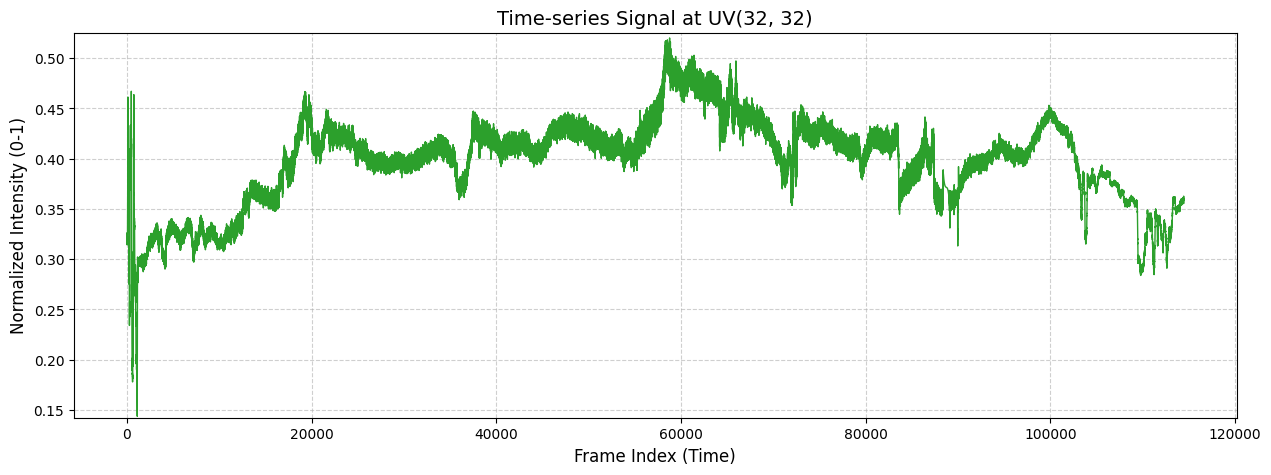

(114422,)


In [61]:
#Test mean 3x3 point

r,c = top4_coor[0][0] , top4_coor[0][1]
box = 5
half = box//2

roi_pixels = data[:, r-1 : r + 2, c-1 : c + 2]
nonzero_count = (roi_pixels > 0).sum(axis=(1, 2))
avg_sig = roi_pixels.sum(axis=(1,2)) / (nonzero_count + 1e-6) # 0으로 나누기 방지

print(avg_sig.shape)

s = pd.Series(avg_sig)
z_loc = (avg_sig == 0)
s[z_loc] = np.nan 
avg_sig_interpolated = s.interpolate(method = 'pchip')
avg_sig_interpolated = avg_sig_interpolated.to_numpy()


plt.figure(figsize=(15, 5))
plt.plot(avg_sig_interpolated, color='#2ca02c', linewidth=1) # rPPG 시각화에 자주 쓰이는 초록 계열

# 3. 그래프 정보 설정
plt.title("Time-series Signal at UV(32, 32)", fontsize=14)
plt.xlabel("Frame Index (Time)", fontsize=12)
plt.ylabel("Normalized Intensity (0-1)", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)

# 4. y축 범위 자동 최적화 (미세한 변화를 보기 위함)
# 만약 정규화된 값의 변화가 너무 작다면 이 부분에서 파형이 뚜렷해집니다.
plt.ylim(avg_sig_interpolated.min() * 0.99, avg_sig_interpolated.max() * 1.01) 

plt.show()
print(avg_sig_interpolated.shape)

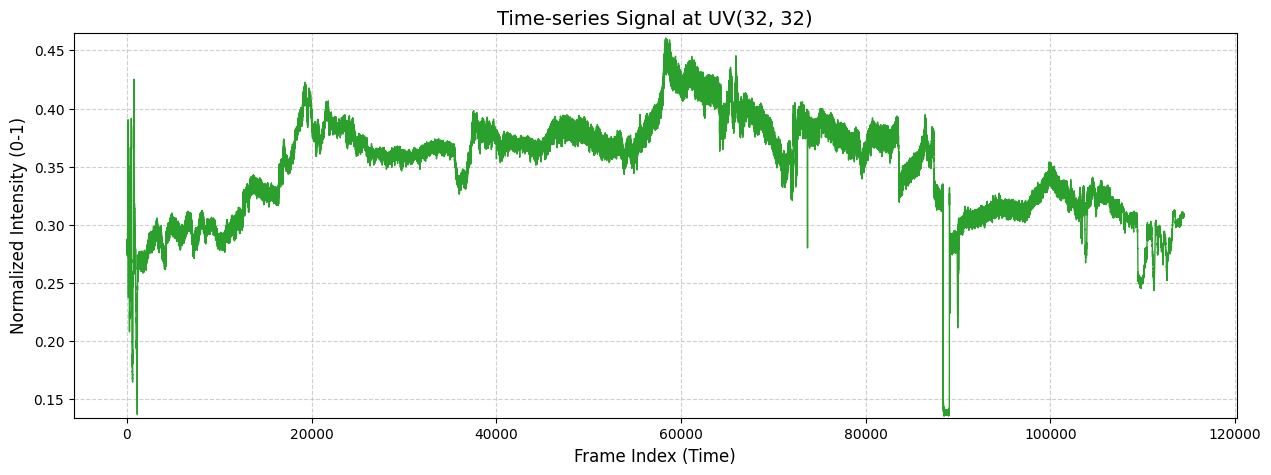

In [60]:
#Test mean 3x3 point by 4 points

avg_sig_sum = np.zeros(114422)

for i in range(len(top4_coor)) :
    coor_t = top4_coor[i]

    r,c = coor_t[0] , coor_t[1]

    roi_pixels = data[:, r-1 : r + 2, c-1 : c + 2]
    nonzero_count = (roi_pixels > 0).sum(axis=(1, 2))
    avg_sig = roi_pixels.sum(axis=(1,2)) / (nonzero_count + 1e-6) # 0으로 나누기 방지
    
    avg_sig_sum += avg_sig

avg_sig_f = avg_sig_sum / len(top4_coor)


plt.figure(figsize=(15, 5))
plt.plot(avg_sig_f, color='#2ca02c', linewidth=1) # rPPG 시각화에 자주 쓰이는 초록 계열

# 3. 그래프 정보 설정
plt.title("Time-series Signal at UV(32, 32)", fontsize=14)
plt.xlabel("Frame Index (Time)", fontsize=12)
plt.ylabel("Normalized Intensity (0-1)", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)

# 4. y축 범위 자동 최적화 (미세한 변화를 보기 위함)
# 만약 정규화된 값의 변화가 너무 작다면 이 부분에서 파형이 뚜렷해집니다.
plt.ylim(avg_sig_f.min() * 0.99, avg_sig_f.max() * 1.01) 

plt.show()

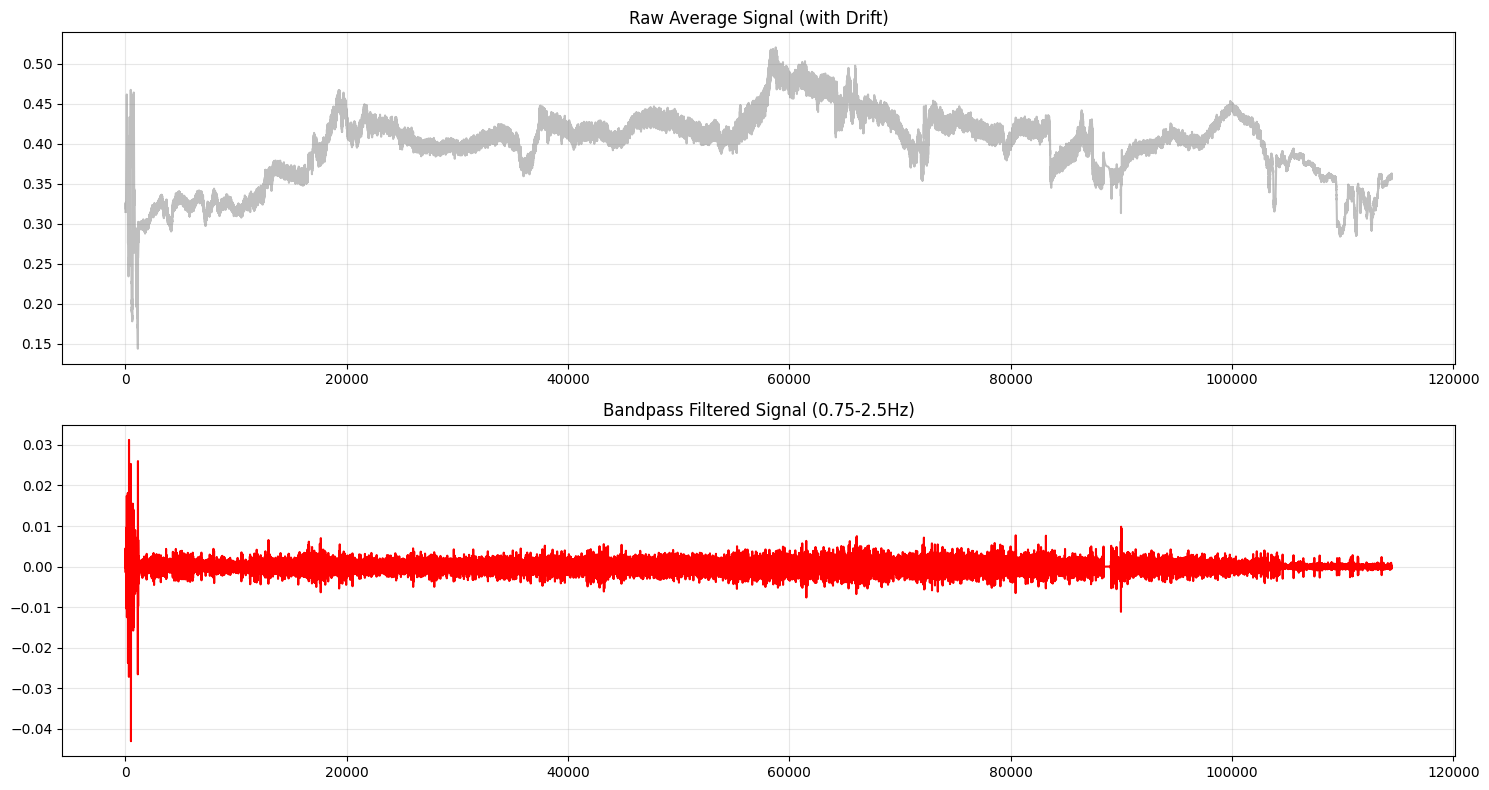

In [62]:
from scipy.signal import butter, filtfilt
from scipy import signal 

def butter_bandpass_filter(data, lowcut, highcut, fs, order=4):
    nyq = 0.5 * fs # 나이퀴스트 주파수
    low = lowcut / nyq
    high = highcut / nyq
    # 버터워스 필터 설계
    b, a = butter(order, [low, high], btype='band')
    # filtfilt를 사용하여 위상 지연 없이 필터링
    y = filtfilt(b, a, data)
    return y

# --- 파라미터 설정 ---
fs = 30.0       # 영상의 FPS (사용자님의 비디오 정보를 꼭 확인하세요)
lowcut = 0.75    # 45 BPM
highcut = 2.5   # 150 BPM

# 1. 텐서를 넘파이 배열로 변환
raw_sig = avg_sig_interpolated

# 2. detrending
detrended_sig = signal.detrend(raw_sig) 

# 3. 필터 적용
filtered_sig = butter_bandpass_filter(detrended_sig, lowcut, highcut, fs, order=2)

# 4. 시각화 (원본 vs 필터링 비교)
plt.figure(figsize=(15, 8))

plt.subplot(2, 1, 1)
plt.plot(raw_sig, color='gray', alpha=0.5)
plt.title("Raw Average Signal (with Drift)")
plt.grid(True, alpha=0.3)

plt.subplot(2, 1, 2)
plt.plot(filtered_sig, color='red')
plt.title(f"Bandpass Filtered Signal ({lowcut}-{highcut}Hz)")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### rppg 추출(425)

In [194]:
data = sub_data
T, H, W = data.shape
left_chick_r = roi_point[1]
left_chick_c = roi_point[0]

right_chick_r = roi_point[1]
right_chock_c = ((64 - roi_point[0])).astype(int)

print(f'왼쪽볼 좌표 : {left_chick_r, left_chick_c} 오른쪽볼 좌표 : {right_chick_r, right_chock_c} ')

왼쪽볼 좌표 : (36, 43) 오른쪽볼 좌표 : (36, 21) 


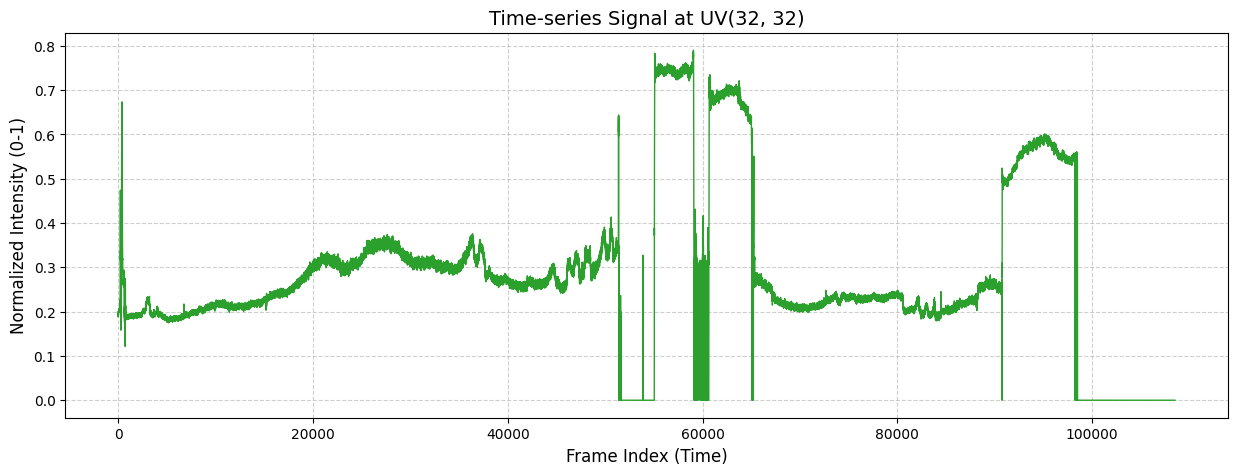

In [197]:
reg = data[:, left_chick_r, left_chick_c ]
reg.shape
reg = reg

# 2. 간단한 시계열 플롯 생성
plt.figure(figsize=(15, 5))
plt.plot(reg, color='#2ca02c', linewidth=1) # rPPG 시각화에 자주 쓰이는 초록 계열

# 3. 그래프 정보 설정
plt.title("Time-series Signal at UV(32, 32)", fontsize=14)
plt.xlabel("Frame Index (Time)", fontsize=12)
plt.ylabel("Normalized Intensity (0-1)", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)

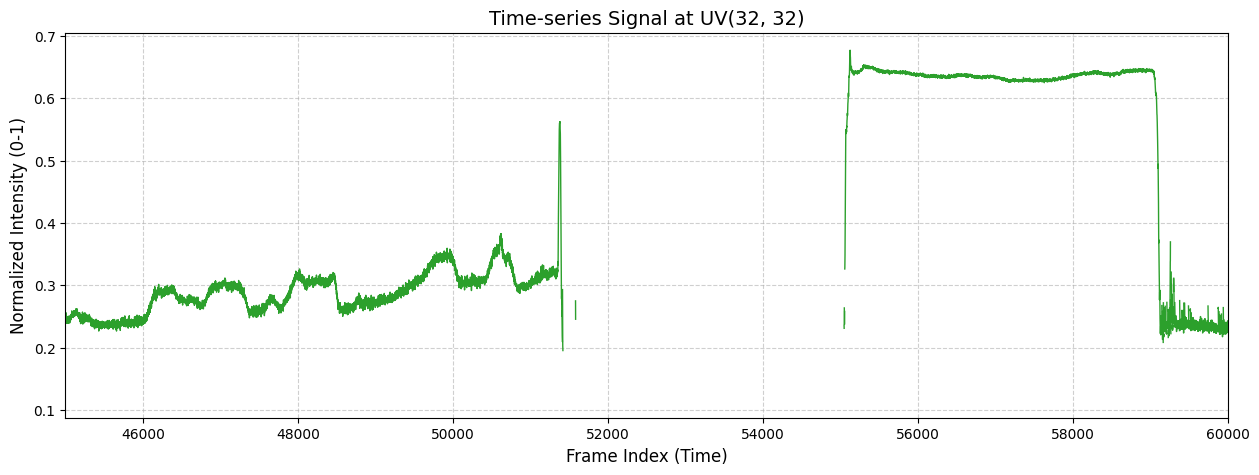

(108505,)


In [199]:
#Test mean 3x3 point

r,c = left_chick_r , left_chick_c
box = 5
half = box//2

roi_pixels = data[: , r-1 : r + 2, c-1 : c + 2]
nonzero_count = (roi_pixels > 0).sum(axis=(1, 2))
avg_sig = roi_pixels.sum(axis=(1,2)) / (nonzero_count + 1e-8) # 0으로 나누기 방지

#print(avg_sig.shape)

s = pd.Series(avg_sig)
z_loc = (avg_sig == 0)
s[z_loc] = np.nan 
avg_sig_interpolated = s.interpolate(method = 'pchip')
avg_sig_interpolated = avg_sig_interpolated.to_numpy()

plt.figure(figsize=(15, 5))
plt.plot(avg_sig, color='#2ca02c', linewidth=1) # rPPG 시각화에 자주 쓰이는 초록 계열

# 3. 그래프 정보 설정
plt.title("Time-series Signal at UV(32, 32)", fontsize=14)
plt.xlabel("Frame Index (Time)", fontsize=12)
plt.ylabel("Normalized Intensity (0-1)", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)

# 4. y축 범위 자동 최적화 (미세한 변화를 보기 위함)
# 만약 정규화된 값의 변화가 너무 작다면 이 부분에서 파형이 뚜렷해집니다.
plt.xlim(45000,60000)
#plt.ylim(0.3, 0.34) 
#plt.ylim(avg_sig_interpolated.min() * 0.99, avg_sig_interpolated.max() * 1.01) 

plt.show()
print(avg_sig_interpolated.shape)

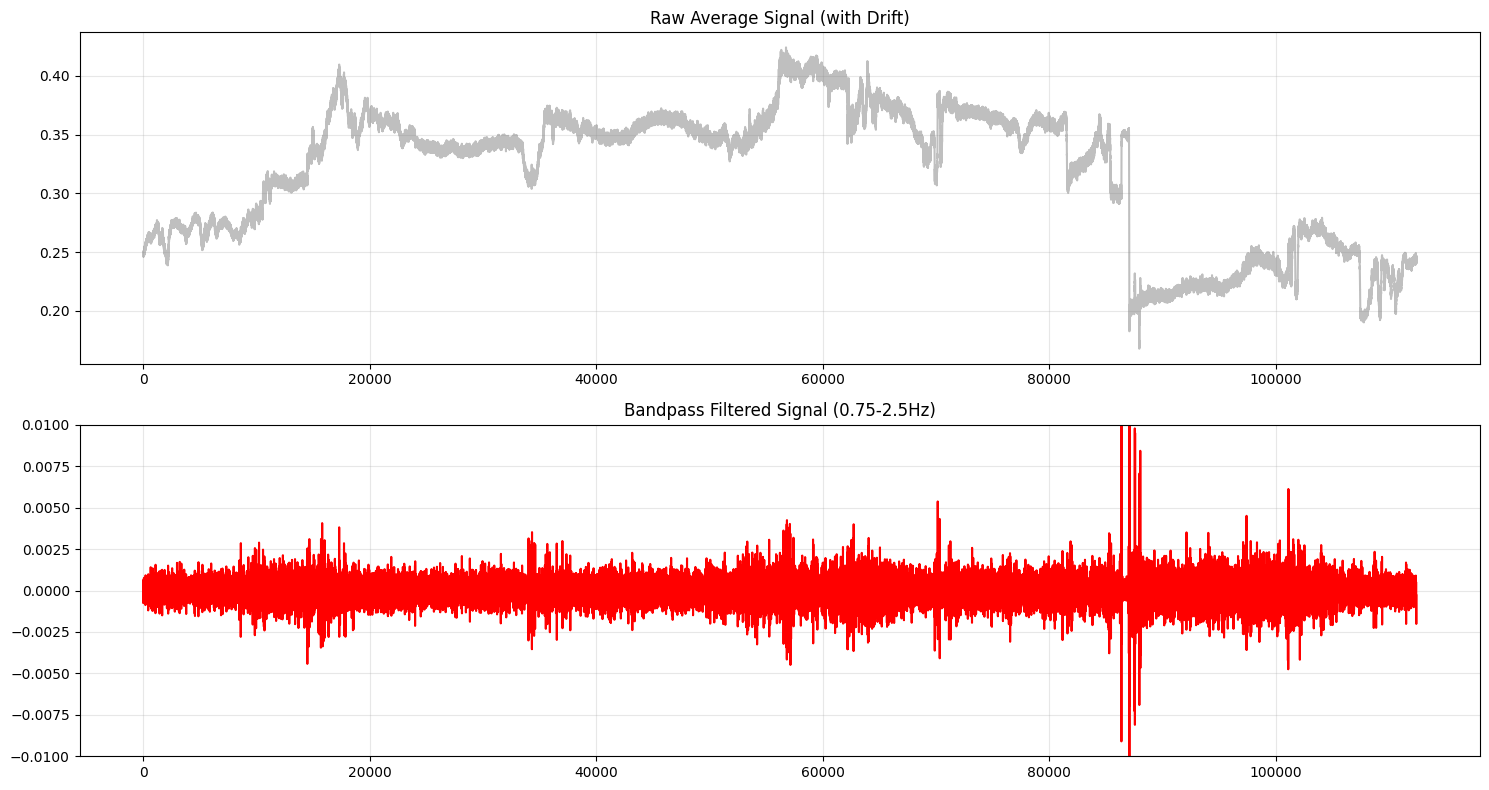

In [33]:
from scipy.signal import butter, filtfilt
from scipy import signal 

def butter_bandpass_filter(data, lowcut, highcut, fs, order=4):
    nyq = 0.5 * fs # 나이퀴스트 주파수
    low = lowcut / nyq
    high = highcut / nyq
    # 버터워스 필터 설계
    b, a = butter(order, [low, high], btype='band')
    # filtfilt를 사용하여 위상 지연 없이 필터링
    y = filtfilt(b, a, data)
    return y

# --- 파라미터 설정 ---
fs = 30.0       # 영상의 FPS (사용자님의 비디오 정보를 꼭 확인하세요)
lowcut = 0.75    # 45 BPM
highcut = 2.5   # 150 BPM

# 1. 텐서를 넘파이 배열로 변환
raw_sig = avg_sig_interpolated

# 2. detrending
detrended_sig = signal.detrend(raw_sig) 

# 3. 필터 적용
filtered_sig = butter_bandpass_filter(detrended_sig, lowcut, highcut, fs, order=2)

# 4. 시각화 (원본 vs 필터링 비교)
plt.figure(figsize=(15, 8))

plt.subplot(2, 1, 1)
plt.plot(raw_sig, color='gray', alpha=0.5)
plt.title("Raw Average Signal (with Drift)")
plt.grid(True, alpha=0.3)

plt.subplot(2, 1, 2)
plt.plot(filtered_sig, color='red')
plt.title(f"Bandpass Filtered Signal ({lowcut}-{highcut}Hz)")
#plt.xlim(10000,10030)
plt.ylim(-0.01,0.01)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### rppg slicing by window

In [163]:
data = sub_data

roi_point = (uv_numpy[425] * 64).astype(int)
T, H, W = data.shape
left_chick_r = roi_point[1]
left_chick_c = roi_point[0]

right_chick_r = roi_point[1]
right_chock_c = ((64 - roi_point[0])).astype(int)

print(f'왼쪽볼 좌표 : {left_chick_r, left_chick_c} 오른쪽볼 좌표 : {right_chick_r, right_chock_c} ')

r,c = left_chick_r , left_chick_c
box = 5
half = box//2
data = sub_data

roi_pixels = data[: , r-1 : r + 2, c-1 : c + 2]
nonzero_count = (roi_pixels > 0).sum(axis=(1, 2))
avg_sig_sl = roi_pixels.sum(axis=(1,2)) / (nonzero_count + 1e-8) # 0으로 나누기 방지

왼쪽볼 좌표 : (36, 43) 오른쪽볼 좌표 : (36, 21) 


In [164]:
from scipy.signal import butter, filtfilt
from scipy import signal 

def z_norm(sig) :
    return( (sig - np.mean(sig)) / np.std(sig) )

def butter_bandpass_filter(data, lowcut, highcut, fs, order=4):
    nyq = 0.5 * fs # 나이퀴스트 주파수
    low = lowcut / nyq
    high = highcut / nyq
    # 버터워스 필터 설계
    b, a = butter(order, [low, high], btype='band')
    # filtfilt를 사용하여 위상 지연 없이 필터링
    y = filtfilt(b, a, data)
    return y

def process_rppg_windows(avg_sig, sub_valid, window_size=900, max_gap_threshold=30):
    """
    rPPG 신호를 윈도우 단위로 자르고, 결손 구간 길이에 따라 보간 또는 폐기합니다.
    
    Args:
        avg_sig (np.array): 원본 rPPG 신호 (intensity)
        sub_valid (np.array): 랜드마크 추출 성공 여부 (True/False)
        window_size (int): 윈도우 크기 (기본 900 프레임 = 30초)
        max_gap_threshold (int): 허용하는 최대 연속 결손 프레임 수 (기본 30 프레임 = 1초)
        
    Returns:
        valid_windows (dict): {윈도우_인덱스: 보간된_신호_배열} 형태의 딕셔너리
        discarded_indices (list): 폐기된 윈도우의 인덱스 리스트
    """
    
    fs = 30.0       # 영상의 FPS 
    lowcut = 0.75    # 45 BPM
    highcut = 2.5   # 150 BPM

    # 1. 원본 신호에 NaN 할당 (False인 구간)
    sig_with_nan = avg_sig.copy()
    sig_with_nan[~sub_valid] = np.nan
    
    # Pandas Series로 변환 (interpolate 함수 사용을 위해)
    sig_series = pd.Series(sig_with_nan)
    
    n_samples = len(sig_series)
    n_windows = n_samples // window_size
    
    valid_windows = {}
    discarded_indices = []
    
    print(f"총 {n_windows}개의 윈도우를 처리합니다...")
    
    for i in range(n_windows):
        start_idx = i * window_size
        end_idx = start_idx + window_size
        
        # 현재 윈도우 추출
        window = sig_series.iloc[start_idx:end_idx].copy()
        
        # --- [핵심 로직] 연속된 NaN 길이 계산 ---
        # 1. NaN 여부를 나타내는 불리언 마스크 생성
        is_nan = window.isna()
        
        # 2. 연속된 그룹(True/False 변화)을 식별하기 위해 diff()와 cumsum() 사용
        #    값이 바뀌는 지점마다 그룹 번호가 증가함
        groups = (is_nan != is_nan.shift()).cumsum()
        
        # 3. 각 그룹별 길이 계산 후, NaN인 그룹만 필터링하여 최대 길이 찾기
        nan_groups = is_nan.groupby(groups)
        # NaN인 그룹의 길이만 추출 (그룹의 첫 값이 True인 경우)
        gap_lengths = nan_groups.size()[nan_groups.first()]
        
        # 윈도우 내 최대 결손 길이 (없으면 0)
        max_gap = gap_lengths.max() if not gap_lengths.empty else 0
        
        # --- [판단] 보간 vs 폐기 ---
        if max_gap >= max_gap_threshold:
            # 기준 초과 시 폐기
            discarded_indices.append(i)
        else:
            # 기준 만족 시 보간 (PCHIP)
            # 양 끝단에 NaN이 있을 경우를 대비해 limit_direction='both' 설정
            # PCHIP은 데이터가 너무 적으면(2개 미만) 실패할 수 있으므로 예외처리
            try:
                if window.notna().sum() > 1:
                    interpolated_window = window.interpolate(method='pchip', limit_direction='both')
                    
                    # PCHIP이 끝단 보간을 못 하는 경우 선형 보간으로 마무으리 (방어 코드)
                    if interpolated_window.isna().any():
                        interpolated_window = interpolated_window.interpolate(method='linear', limit_direction='both')

                    detrend_sig = signal.detrend(interpolated_window) 

                    # 필터 적용
                    filter_sig = butter_bandpass_filter(detrend_sig, lowcut, highcut, fs, order=2)

                    f_sig = z_norm(filter_sig)

                    valid_windows[i] = f_sig

                else:
                    discarded_indices.append(i) # 데이터가 거의 없는 경우
            except Exception as e:
                print(f'Error : {e}')
                discarded_indices.append(i)

    print(f"처리 완료: 유효 윈도우 {len(valid_windows)}개, 폐기 윈도우 {len(discarded_indices)}개")
    return valid_windows, discarded_indices

In [169]:
ppg_windows, discarded_indices = process_rppg_windows(avg_sig_sl, sub_valid, window_size=900, max_gap_threshold= 30)

총 133개의 윈도우를 처리합니다...
처리 완료: 유효 윈도우 79개, 폐기 윈도우 54개


### ppg downsampling / slicing

In [245]:
# 새로운비교
import pandas as pd

subject_num = 1
subject_id = subject_lists[subject_num].split('[')[1].split(']')[0]


ppg_cut_dir = '/nasdata2/2yhy/CNA_ours_IRB/edited/final_report_ppg/' #ppg cut
ppg_dir = '/nasdata2/2yhy/CNA_ours_IRB/edited/final_report_ppg/raw_data_link/CNA_members/csv/ppg_raw' #ppg 원본
base_dir_1 = '/nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/videos/' #비디오 원본


people_list_2 = ['A001_250609_cut.csv', 'A002_250609_cut.csv', 'A004_250610_cut.csv', 'A005_250611_cut.csv', 
'A006_250611_cut.csv', 'A007_250612_cut.csv', 'A008_250612_cut.csv', 'B001_250623_cut.csv', 'B002_250623_cut.csv', 
'B003_250624_cut.csv', 'B004_250624_cut.csv', 'B005_250625_cut.csv', 'B008_250627_cut.csv', 'C001_250701_cut.csv', 'C002_250703_cut.csv', 'C003_250702_cut.csv']
clean_list = [name.replace('_cut', '') for name in people_list_2]
people = sorted([f for f in os.listdir(base_dir_1)])
subject_nnuum = subject_num

cut_ppg_root = os.path.join(ppg_cut_dir, people_list_2[subject_nnuum]) # cut ppg 루트
raw_ppg_root = os.path.join(ppg_dir, clean_list[subject_nnuum])
vp1 = os.path.join(base_dir_1,people[subject_nnuum],'NIR') # 원본비디오루트

ppg_file_id = people_list_2[subject_nnuum][:5]+'20'+people_list_2[subject_nnuum][5:11]

assert subject_id == ppg_file_id, f"ppg, rppg 데이터 불일치 경고 {subject_id} 와 {ppg_file_id}가 다릅니다."

### subject 설정
ppg_cut = pd.read_csv(cut_ppg_root)
ppg_orig = pd.read_csv(raw_ppg_root)


print(f"ppg_원본 수 {ppg_orig.shape}")
print(f"ppg_cut 수 {ppg_cut.shape}")
print(f"이전비디오결과 총 프레임 수 : {len(os.listdir(vp1))} ")
print(f'raw_ppg downsampling후 개수 : {ppg_orig.shape[0] * (30/500)}')
print(f'cut_ppg downsampling후 개수 : {ppg_cut.shape[0] * (30/500)}')





# raw_video_root = '/nasdata2/2yhy/CNA_ours_IRB/raw_frame_files/CNA_member_raw_frames'
# reraw_ppg_root = '/nasdata2/2yhy/CNA_ours_IRB/edited/final_report_ppg/raw_data_link/CNA_members/csv/ppg_raw'
# raw_video_people = sorted(os.listdir(raw_video_root))
# raw_video_people = raw_video_people[:-1]
# reraw_ppg_people = sorted(os.listdir(reraw_ppg_root))
# print(reraw_ppg_people)
# print(raw_video_people)



ppg_원본 수 (2077696, 14)
ppg_cut 수 (2021813, 1)
이전비디오결과 총 프레임 수 : 114227 
raw_ppg downsampling후 개수 : 124661.76
cut_ppg downsampling후 개수 : 121308.78


In [178]:
# 1. 원본 / 설정값
fs_origin = 500
fs_target =30
ppg_segment = ppg_cut

# 2. downsampling

ppg_downsampled = signal.resample(ppg_segment, data.shape[0])

# 3. 확인
print(f"다운 샘플링 후 샘플 수 : {ppg_downsampled.shape}")
print(f"원본 영상 프레임 수 : {data.shape[0]}")

다운 샘플링 후 샘플 수 : (120592, 1)
원본 영상 프레임 수 : 120592


In [64]:
# z normalization to compare with
def z_norm(sig) :
    return( (sig - np.mean(sig)) / np.std(sig) )

rppg_z = z_norm(filtered_sig[2000:])
ppg_z = z_norm(butter_bandpass_filter(ppg_downsampled[2000:].reshape(-1), lowcut, highcut, fs, order=2))
ppg_z_2 = z_norm(butter_bandpass_filter(ppg_orig.to_numpy().reshape(-1), lowcut, highcut, fs, order=2))

print(f"rppg shape : {rppg_z.shape}, ppg shape : {ppg_z.shape}")

rppg shape : (112422,), ppg shape : (112422,)


In [184]:
def ppg_to_window(ppg, fail_index, window_size=900) : 
    
    ppg_win_n = len(ppg) // window_size
    ppg_u = ppg.flatten().copy()

    ppg_windows = {}


    for i in range( ppg_win_n ) : 
        if i not in fail_index :
            start_ind = i * window_size
            end_ind = start_ind + window_size

            detrend_sig = signal.detrend( ppg_u[start_ind : end_ind] )
            ppg_f = butter_bandpass_filter( detrend_sig , 0.75, 2.5, 30, order=2 )
            ppg_z = z_norm(ppg_f)

            ppg_windows[i] = ppg_z
        
        else : 
            continue
    
    return ppg_windows

In [185]:
rppg_windows = ppg_to_window(ppg_downsampled, discarded_indices, window_size=900 )

# 결과비교

### comapare in time domain

In [ ]:
plt.figure(figsize=(20, 8))

plt.subplot(3, 1, 1)
plt.plot(rppg_z, color='red', alpha=0.5)
plt.title("rppg")
plt.xlabel('Frame Index(30FPS)')
plt.ylabel('z-Normalized amplitude')
plt.grid(True, alpha=0.3)

plt.subplot(3, 1, 2)
plt.plot(ppg_z, color='blue')
plt.title(f"ppg")
plt.xlabel('Frame Index(30FPS)')
plt.ylabel('z-Normalized amplitude')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize = (15,5))

plt.plot(ppg_z, label ='Ground Truth(ppg)', color = 'blue', alpha = 0.5, linewidth = 2)
plt.plot(rppg_z, label = 'rppg', color = 'red', alpha = 0.7, linestyle = '--')

plt.title('rppg vs ppg')
plt.xlabel('Frame Index(30FPS)')
plt.ylabel('z-Normalized amplitude')
plt.legend(loc = 'upper right')
plt.grid(True, axis='y', linestyle='--', alpha=0.6)

plt.xlim(0,1000) ## 특정구간 관찰
plt.ylim(-5,5) ## 특정구간 관찰

plt.show()

### compare in frequency domain(hr)

In [67]:
# signal fft
import numpy as np
from scipy.fft import fft
from scipy import signal
from scipy.signal import butter, filtfilt

def hr_fft(sig, fs, harmonics_removal=True):
    # get heart rate by FFT
    # return both heart rate and PSD

    sig = sig.reshape(-1)
    sig = sig * signal.windows.hann(sig.shape[0])
    sig_f = np.abs(fft(sig))
    low_idx = np.round(0.75 / fs * sig.shape[0]).astype('int')
    high_idx = np.round(2.5 / fs * sig.shape[0]).astype('int')
    sig_f_original = sig_f.copy()
    
    sig_f[:low_idx] = 0
    sig_f[high_idx:] = 0

    peak_idx, _ = signal.find_peaks(sig_f)
    sort_idx = np.argsort(sig_f[peak_idx])
    sort_idx = sort_idx[::-1]

    peak_idx1 = peak_idx[sort_idx[0]]
    peak_idx2 = peak_idx[sort_idx[1]]

    f_hr1 = peak_idx1 / sig.shape[0] * fs
    hr1 = f_hr1 * 60

    f_hr2 = peak_idx2 / sig.shape[0] * fs
    hr2 = f_hr2 * 60
    if harmonics_removal:
        if np.abs(hr1-2*hr2)<10:
            hr = hr2
        else:
            hr = hr1
    else:
        hr = hr1

    x_hr = np.arange(len(sig))/len(sig)*fs*60
    return hr, sig_f_original, x_hr

In [71]:
# Get highest bpm for MAE
ae_list = []

k = 5400

for i in range( 0, data.shape[0], k) :
    start_idex = i
    end_idex = i + k

    hr_ppg, psd_ppg, axis_ppg = hr_fft(ppg_z[ start_idex : end_idex ], fs =30)
    hr_rppg, psd_rppg, axis_rppg = hr_fft(rppg_z[ start_idex : end_idex ], fs =30)
    ae = abs(hr_ppg - hr_rppg)
    ae_list.append(ae)


mae = np.mean(ae_list)

print(f"mae : {mae}")

mae : 16.101505459714414


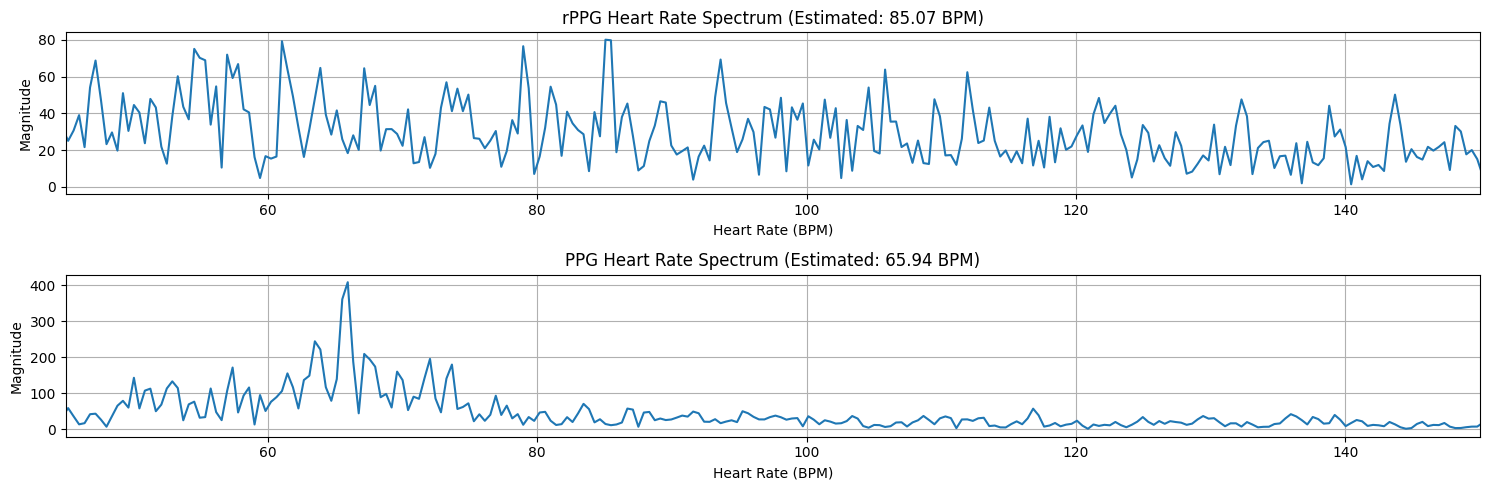

In [72]:
plt.figure(figsize=(15, 5))

plt.subplot(2,1,1)
plt.plot(axis_rppg, psd_rppg) # x축은 bpm_axis(3번째 리턴), y축은 psd(2번째 리턴)
plt.title(f"rPPG Heart Rate Spectrum (Estimated: {hr_rppg:.2f} BPM)")
plt.xlabel("Heart Rate (BPM)")
plt.ylabel("Magnitude")
plt.xlim(45, 150)
plt.grid(True)

plt.subplot(2,1,2)
plt.plot(axis_ppg, psd_ppg) # x축은 bpm_axis(3번째 리턴), y축은 psd(2번째 리턴)
plt.title(f"PPG Heart Rate Spectrum (Estimated: {hr_ppg:.2f} BPM)")
plt.xlabel("Heart Rate (BPM)")
plt.ylabel("Magnitude")
plt.xlim(45, 150)
plt.grid(True)

plt.tight_layout()
plt.show()

### hrv / hr 지표 비교

In [54]:
from scipy.signal import find_peaks
from astropy.timeseries import LombScargle
import neurokit2 as nk


def get_ibi(sig, sig_fps):
    ppg_clean = nk.ppg_clean(sig.copy(), sampling_rate=sig_fps, method='elgendi')
    info = nk.ppg_findpeaks(ppg_clean,sampling_rate=sig_fps)
    peak_loc = info["PPG_Peaks"]
    
    IBI = (peak_loc[1:]-peak_loc[0:-1])/sig_fps
    return IBI

def freq_features(ibi):
    
    def find_highest_peak(sig):
        peak_loc = find_peaks(sig)[0]
        peak_amp = sig[peak_loc]
        highest_peak_loc = np.argmax(peak_amp)
        peak_loc = peak_loc[highest_peak_loc]
        return peak_loc
    
    freq,power = LombScargle(np.cumsum(ibi), ibi).autopower(minimum_frequency=0.01,maximum_frequency=0.51)
    idx_lf = np.where((freq>0.04)*(freq<0.15))
    idx_hf = np.where((freq>0.15)*(freq<0.40))
    
    freq_lf = freq[idx_lf]
    power_lf = np.sum(power[idx_lf])
    peak_loc_lf= find_highest_peak(power[idx_lf])
    
    freq_hf = freq[idx_hf]
    power_hf = np.sum(power[idx_hf])
    peak_loc_hf= find_highest_peak(power[idx_hf])
    
    f_list = {'lf_f' : [], 'hf_f' : [], 'lfnu' : [], 'hfnu' : [], 'lf_hf_ratio' : []}
    f_list['lf_f'].append(freq_lf[peak_loc_lf]) # lf_f
    f_list['hf_f'].append(freq_hf[peak_loc_hf]) # hf_f
    f_list['lfnu'].append(power_lf / (power_lf+power_hf)) # lfnu
    f_list['hfnu'].append(power_hf / (power_lf+power_hf)) # hfnu
    f_list['lf_hf_ratio'].append(power_lf / power_hf) # lf_hf_ratio
    return f_list

In [55]:
ppg_gt = z_norm(butter_bandpass_filter(ppg_segment.to_numpy().reshape(-1), lowcut, highcut, fs, order=2))
ibi_ppg = get_ibi(ppg_gt, sig_fps = 500)
hrv_ppg = freq_features(ibi_ppg)

ibi_rppg = get_ibi(rppg_z, sig_fps = 30)
hrv_rppg = freq_features(ibi_rppg)

print(hrv_ppg)
print(hrv_rppg)

{'lf_f': [0.11214701747040642], 'hf_f': [0.23418894822720018], 'lfnu': [0.3543405064023356], 'hfnu': [0.6456594935976644], 'lf_hf_ratio': [0.5488039902084039]}
{'lf_f': [0.12415147227635574], 'hf_f': [0.1784508395846129], 'lfnu': [0.3161000847070026], 'hfnu': [0.6838999152929974], 'lf_hf_ratio': [0.4622022574334997]}


# 경로찾기

In [ ]:
# 새로운비교
import pandas as pd

subject_num = 1
subject_id = subject_lists[subject_num].split('[')[1].split(']')[0]


ppg_cut_dir = '/nasdata2/2yhy/CNA_ours_IRB/edited/final_report_ppg/' #ppg cut
ppg_dir = '/nasdata2/2yhy/CNA_ours_IRB/edited/final_report_ppg/raw_data_link/CNA_members/csv/ppg_raw' #ppg 원본
base_dir_1 = '/nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/videos/' #비디오 원본


people_list_2 = ['A001_250609_cut.csv', 'A002_250609_cut.csv', 'A004_250610_cut.csv', 'A005_250611_cut.csv', 
'A006_250611_cut.csv', 'A007_250612_cut.csv', 'A008_250612_cut.csv', 'B001_250623_cut.csv', 'B002_250623_cut.csv', 
'B003_250624_cut.csv', 'B004_250624_cut.csv', 'B005_250625_cut.csv', 'B008_250627_cut.csv', 'C001_250701_cut.csv', 'C002_250703_cut.csv', 'C003_250702_cut.csv']
clean_list = [name.replace('_cut', '') for name in people_list_2]
people = sorted([f for f in os.listdir(base_dir_1)])
subject_nnuum = subject_num

cut_ppg_root = os.path.join(ppg_cut_dir, people_list_2[subject_nnuum]) # cut ppg 루트
raw_ppg_root = os.path.join(ppg_dir, clean_list[subject_nnuum])
vp1 = os.path.join(base_dir_1,people[subject_nnuum],'NIR') # 원본비디오루트

ppg_file_id = people_list_2[subject_nnuum][:5]+'20'+people_list_2[subject_nnuum][5:11]

assert subject_id == ppg_file_id, f"ppg, rppg 데이터 불일치 경고 {subject_id} 와 {ppg_file_id}가 다릅니다."

### subject 설정
ppg_cut = pd.read_csv(cut_ppg_root)
ppg_orig = pd.read_csv(raw_ppg_root)


print(f"ppg_원본 수 {ppg_orig.shape}")
print(f"ppg_cut 수 {ppg_cut.shape}")
print(f"이전비디오결과 총 프레임 수 : {len(os.listdir(vp1))} ")
print(f'raw_ppg downsampling후 개수 : {ppg_orig.shape[0] * (30/500)}')
print(f'cut_ppg downsampling후 개수 : {ppg_cut.shape[0] * (30/500)}')


import pandas as pd
all_dicts = {}
sub_dicts = {'frame' : 0 , 'time' : 0.0}
for i in range(len(people)) :
    subject_num = i
    # print(f"subject : {people[subject_num]}")
    vp1 = os.path.join(base_dir_1,people[subject_num],'NIR') # 원본비디오루트
    # print(f"비디오결과 총 프레임 수 : {len(os.listdir(vp1))} ")
    # print(f'시간 : {np.array(len(os.listdir(vp1))/30)}s')
    sub_dicts['frame'] = (len(os.listdir(vp1)))
    sub_dicts['time'] = (np.round(np.array(len(os.listdir(vp1))/30),3))
    all_dicts[people[subject_num]]= sub_dicts
    sub_dicts = {'frame' : 0 , 'time' : 0.0}

#ig = cv2.imread(os.path.join(vp1,os.listdir(vp1)[0]))
#plt.imshow(ig)
df_vd = pd.DataFrame(all_dicts)
display(df_vd)


raw_video_root = '/nasdata2/2yhy/CNA_ours_IRB/raw_frame_files/CNA_member_raw_frames'
reraw_ppg_root = '/nasdata2/2yhy/CNA_ours_IRB/edited/final_report_ppg/raw_data_link/CNA_members/csv/ppg_raw'
raw_video_people = sorted(os.listdir(raw_video_root))
raw_video_people = raw_video_people[:-1]
reraw_ppg_people = sorted(os.listdir(reraw_ppg_root))
print(reraw_ppg_people)
print(raw_video_people)



In [39]:
import pandas as pd
all_dicts = {}
sub_dicts = {'frame' : 0 , 'time' : 0.0}
base_dir_1 = '/nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/videos/' #비디오 원본
people = sorted([f for f in os.listdir(base_dir_1)])
for i in range(len(people)) :
    subject_num = i
    # print(f"subject : {people[subject_num]}")
    vp1 = os.path.join(base_dir_1,people[subject_num],'NIR') # 원본비디오루트
    # print(f"비디오결과 총 프레임 수 : {len(os.listdir(vp1))} ")
    # print(f'시간 : {np.array(len(os.listdir(vp1))/30)}s')
    sub_dicts['frame'] = (len(os.listdir(vp1)))
    sub_dicts['time'] = (np.round(np.array(len(os.listdir(vp1))/30),3))
    all_dicts[people[subject_num]]= sub_dicts
    sub_dicts = {'frame' : 0 , 'time' : 0.0}

#ig = cv2.imread(os.path.join(vp1,os.listdir(vp1)[0]))
#plt.imshow(ig)
df_vd = pd.DataFrame(all_dicts)
display(df_vd)

,A001_20250609,A002_20250609,A004_20250610,A005_20250611,A006_20250611,A007_20250612,A008_20250612,B001_20250623,B002_20250623,B003_20250624,B004_20250624,B005_20250625,B008_20250627,C001_20250701,C002_20250703,C003_20250702
frame,107727.0,114227.000,114422.000,120275.000,104291.000,120592.000,116806.000,117048.0,119636.000,106143.0,106635.0,127331.000,104772.0,108505.000,117465.0,107411.000
time,3590.9,3807.567,3814.067,4009.167,3476.367,4019.733,3893.533,3901.6,3987.867,3538.1,3554.5,4244.367,3492.4,3616.833,3915.5,3580.367


In [262]:
raw_video_root = '/nasdata2/2yhy/CNA_ours_IRB/raw_frame_files/CNA_member_raw_frames' # 해당 폴더 프레임수 확인
pp = sorted(os.listdir(raw_video_root))
pp = pp[:-1]
#raw_video_root_2 = os.path.join(raw_video_root,pp[1])


all_dictsss = {}
sub_dictsss = {'frame' : 0 , 'time' : 0.0}
for i in range(len(pp)) :
    subject_num = i
    raw_video_root_2 = os.path.join(raw_video_root,pp[i])
    sub_dictsss['frame'] = (len(os.listdir(raw_video_root_2)))
    sub_dictsss['time'] = (np.round(np.array(len(os.listdir(raw_video_root_2))/30),3))
    all_dictsss[pp[subject_num]]= sub_dictsss
    sub_dictsss = {'frame' : 0 , 'time' : 0.0}

#ig = cv2.imread(os.path.join(vp1,os.listdir(vp1)[0]))
#plt.imshow(ig)
df_vdd = pd.DataFrame(all_dictsss)
display(df_vdd)

,A001_20250609,A002_20250609,A003_20250610,A004_20250610,A005_20250611,A006_20250611,A007_20250612,A008_20250612,A009_20250613,B001_20250623,B002_20250623,B003_20250624,B004_20250624,B005_20250625,B006_20250626,B007_20250626,B008_20250627,C001_20250701,C002_20250703,C003_20250702
frame,116727.0,123226.000,116731.000,123421.000,129274.000,113290.000,129591.0,125805.0,115806.0,126047.000,128635.000,115142.000,115634.000,136330.000,123651.0,126474.0,113771.000,117504.0,126464.000,116410.000
time,3890.9,4107.533,3891.033,4114.033,4309.133,3776.333,4319.7,4193.5,3860.2,4201.567,4287.833,3838.067,3854.467,4544.333,4121.7,4215.8,3792.367,3916.8,4215.467,3880.333


In [7]:
reraw_ppg_root = '/nasdata2/2yhy/CNA_ours_IRB/edited/final_report_ppg/raw_data_link/CNA_members/csv/ppg_raw' # 해당 폴더 프레임수 확인 8888이후의 데이터개수를 셈

# 해당 폴더 내의 .csv 파일만 리스트업 후 정렬
csv_files = sorted([f for f in os.listdir(reraw_ppg_root) if f.endswith('.csv')])

all_dictsss = {}

# rpp.iloc[:, -1].value_counts()


PPG_SAMPLING_RATE = 500.0 

for f_name in csv_files:
    # 'A001.csv' 같은 파일명에서 '.csv'를 제거해 과제명(Subject) 추출
    subject_name = f_name.replace('.csv', '') 
    csv_path = os.path.join(reraw_ppg_root, f_name)
    
    # csv 파일을 읽어서 데이터 총 길이(행 개수) 파악
    df = pd.read_csv(csv_path)
    target_indices = df.index[df.iloc[:, -1] == 8888.0].tolist()
    last_num = target_indices[-1]

    rpp_sliced = df.iloc[last_num:, :]
    data_length = rpp_sliced.shape[0]

    # 프레임(길이)과 시간 계산 후 딕셔너리에 저장
    sub_dictsss = {
        'ppg_length': data_length, 
        'time': np.round(data_length / PPG_SAMPLING_RATE, 3)
    }
    
    all_dictsss[subject_name] = sub_dictsss

# DataFrame으로 만들어서 출력
df_ppg = pd.DataFrame(all_dictsss)
display(df_ppg)

,A001_250609,A002_250609,A003_250610,A004_250610,A005_250611,A006_250611,A007_250612,A008_250612,A009_250613,B001_250623,B002_250623,B003_250624,B004_250624,B005_250625,B006_250626,B007_250626,B008_250627,C001_250701,C002_250703,C003_250702
ppg_length,1976992.000,2059285.00,1950623.000,2069989.000,2273208.000,1892009.000,2171503.000,2100800.0,1935999.000,2104245.00,2157986.000,1927561.000,1938962.000,2288230.00,2071912.000,2096552.000,1905575.00,1979777.000,2124074.000,1954991.000
time,3953.984,4118.57,3901.246,4139.978,4546.416,3784.018,4343.006,4201.6,3871.998,4208.49,4315.972,3855.122,3877.924,4576.46,4143.824,4193.104,3811.15,3959.554,4248.148,3909.982


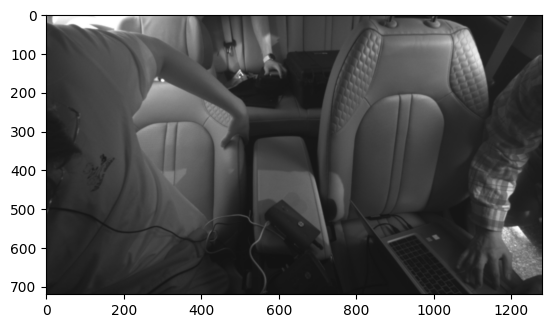

In [38]:
raw_video_root = '/nasdata2/2yhy/CNA_ours_IRB/raw_frame_files/CNA_member_raw_frames' # 해당 폴더 프레임수 확인
pp = sorted(os.listdir(raw_video_root))
pp = pp[:-1]
raw_video_root_1 = os.path.join(raw_video_root,pp[0])
raw_video_root_2 = os.path.join(raw_video_root,pp[0],sorted(os.listdir(raw_video_root_1))[-1])
iii = cv2.imread(raw_video_root_2)
plt.imshow(iii, cmap= 'gray')
